<a href="https://colab.research.google.com/github/viquanghuytt1d24vui/BAITAPTHAOLUAN/blob/master/BaiThucHanh.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

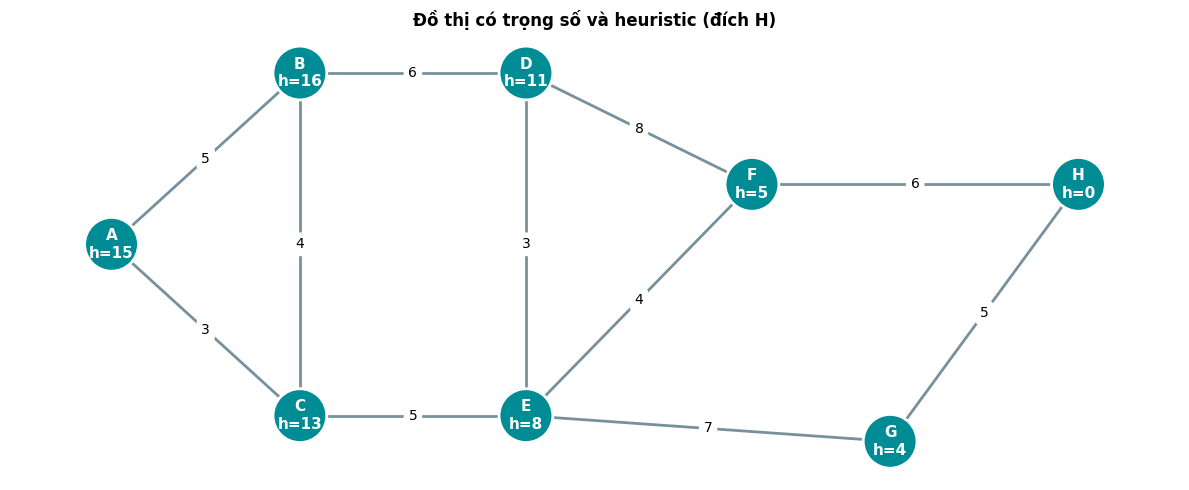

In [23]:
# @title
import networkx as nx
import matplotlib.pyplot as plt
from collections import deque
from IPython.display import display, clear_output
import ipywidgets as widgets

# Danh sách cạnh: (đỉnh 1, đỉnh 2, trọng số)
edges = [
    ('A', 'B', 5), ('A', 'C', 3), ('B', 'C', 4),
    ('B', 'D', 6), ('C', 'E', 5), ('D', 'E', 3),
    ('D', 'F', 8), ('E', 'F', 4), ('E', 'G', 7),
    ('F', 'H', 6), ('G', 'H', 5),
]
heuristic = {'A': 15, 'B': 16, 'C': 13, 'D': 11,
             'E': 8, 'F': 5, 'G': 4, 'H': 0}

# Thứ tự kề cố định giúp bảng vết luôn nhất quán
adjacency = {node: [] for node in heuristic}
for u, v, w in edges:
    adjacency[u].append(v)
    adjacency[v].append(u)

G = nx.Graph()
G.add_weighted_edges_from(edges)
pos = {
    'A': (0, 1), 'B': (1.5, 2), 'C': (1.5, 0),
    'D': (3.3, 2), 'E': (3.3, 0), 'F': (5.1, 1.35),
    'G': (6.2, -0.15), 'H': (7.7, 1.35)
}

def draw_graph(ax, current=None, visited=None, queue=None, path=None,
               title='Đồ thị', show_heuristic=True):
    visited = set() if visited is None else set(visited)
    queue = [] if queue is None else list(queue)
    path = [] if path is None else list(path)
    path_edges = {frozenset((path[i], path[i+1])) for i in range(len(path)-1)}

    colors = []
    for node in G.nodes():
        if node == current:
            colors.append('#FF9800')
        elif node in path:
            colors.append('#00C853')
        elif node in visited:
            colors.append('#90CAF9')
        elif node in queue:
            colors.append('#FFF176')
        else:
            colors.append('#008C95')

    edge_colors = ['#E53935' if frozenset(e) in path_edges else '#78909C'
                   for e in G.edges()]
    edge_widths = [3.5 if frozenset(e) in path_edges else 2 for e in G.edges()]
    nx.draw_networkx_edges(G, pos, ax=ax, edge_color=edge_colors, width=edge_widths)
    nx.draw_networkx_nodes(G, pos, ax=ax, node_color=colors, node_size=1500,
                           edgecolors='white', linewidths=2)

    labels = {n: f'{n}\nh={heuristic[n]}' if show_heuristic else n for n in G.nodes()}
    nx.draw_networkx_labels(G, pos, ax=ax, labels=labels, font_size=11,
                            font_weight='bold', font_color='white')
    nx.draw_networkx_edge_labels(G, pos, ax=ax,
                                 edge_labels={(u, v): w for u, v, w in edges},
                                 font_size=10, rotate=False)
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.axis('off')

fig, ax = plt.subplots(figsize=(12, 5))
draw_graph(ax, title='Đồ thị có trọng số và heuristic (đích H)')
plt.tight_layout()
plt.show()

Phần này chuẩn bị các thư viện để xử lý và trực quan hóa đồ thị. Dữ liệu cạnh chứa hai đỉnh nối với nhau và trọng số của cạnh; bảng heuristic lưu giá trị h tại từng đỉnh. Từ danh sách cạnh, chương trình tạo danh sách các đỉnh kề để các thuật toán tìm kiếm sử dụng. Hàm vẽ đồ thị thể hiện trạng thái các đỉnh bằng màu sắc: đỉnh đang xét, đỉnh đã thăm, đỉnh đang chờ và đỉnh nằm trên đường đi. Trọng số được ghi trên cạnh, còn heuristic được ghi cạnh tên đỉnh.

In [24]:
# @title
def bfs_with_steps(graph, start, goal):
    if start not in graph or goal not in graph:
        raise ValueError('Đỉnh bắt đầu hoặc đích không có trong đồ thị.')
    queue = deque([start])
    visited = {start}
    parent = {start: None}
    steps = []

    while queue:
        current = queue.popleft()
        newly_discovered = []
        if current != goal:
            for neighbor in graph[current]:
                if neighbor not in visited:
                    visited.add(neighbor)
                    parent[neighbor] = current
                    queue.append(neighbor)
                    newly_discovered.append(neighbor)

        steps.append({
            'current': current, 'queue': list(queue), 'visited': set(visited),
            'parent': dict(parent), 'newly_discovered': newly_discovered,
            'found': current == goal
        })
        if current == goal:
            break

    path = []
    if goal in parent:
        node = goal
        while node is not None:
            path.append(node)
            node = parent[node]
        path.reverse()
    return path, steps

start_node, goal_node = 'A', 'H'
path, steps = bfs_with_steps(adjacency, start_node, goal_node)
print('Đỉnh bắt đầu:', start_node)
print('Đỉnh đích:', goal_node)
print('Số bước xử lý:', len(steps))
print('Đường đi BFS:', ' → '.join(path))
print('Số cạnh:', len(path) - 1)
print('Tổng trọng số của đường BFS:', sum(G[u][v]['weight'] for u, v in zip(path, path[1:])))

Đỉnh bắt đầu: A
Đỉnh đích: H
Số bước xử lý: 8
Đường đi BFS: A → B → D → F → H
Số cạnh: 4
Tổng trọng số của đường BFS: 25


BFS bắt đầu bằng cách đưa đỉnh A vào hàng đợi. Mỗi lượt, thuật toán lấy đỉnh ở đầu hàng đợi rồi lần lượt xét các đỉnh kề. Đỉnh nào chưa được phát hiện sẽ được đánh dấu, ghi lại cha và thêm vào cuối hàng đợi. Việc đánh dấu ngay khi phát hiện giúp tránh đưa cùng một đỉnh vào hàng đợi nhiều lần. Sau mỗi lượt, chương trình lưu lại trạng thái để dùng ở các phần trực quan hóa và in bảng. Cuối cùng, chương trình lần theo thông tin cha để tìm đường từ A đến H.

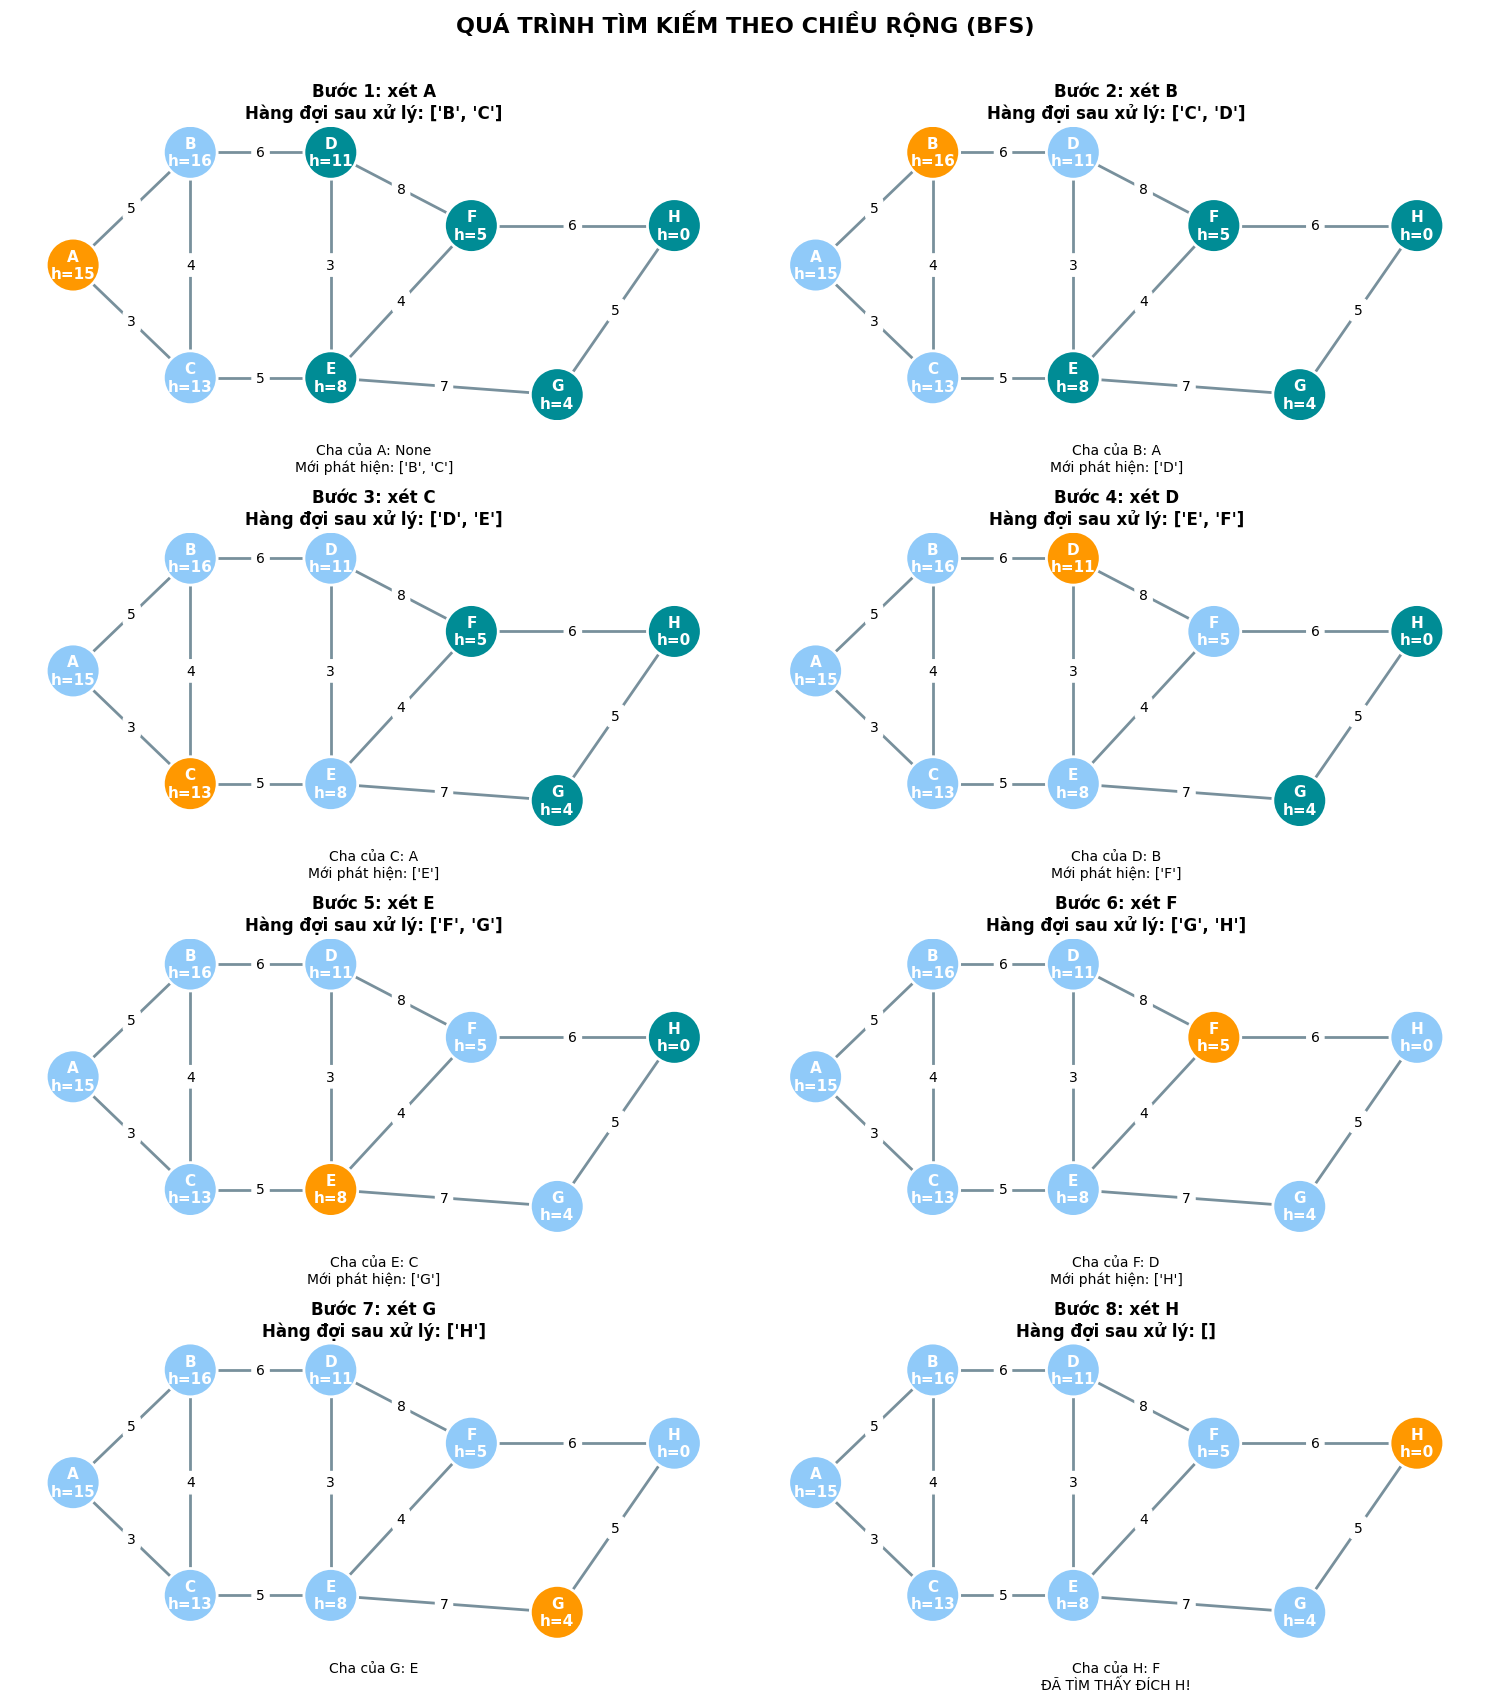

In [25]:
# @title
n_steps = len(steps)
ncols = 2
nrows = (n_steps + ncols - 1) // ncols
fig, axes = plt.subplots(nrows, ncols, figsize=(15, 4.2 * nrows))
axes = axes.flatten()

for i, step in enumerate(steps):
    title = (f"Bước {i + 1}: xét {step['current']}\n"
             f"Hàng đợi sau xử lý: {step['queue']}")
    draw_graph(axes[i], current=step['current'], visited=step['visited'],
               queue=step['queue'], title=title)
    info = f"Cha của {step['current']}: {step['parent'].get(step['current'])}"
    if step['newly_discovered']:
        info += f"\nMới phát hiện: {step['newly_discovered']}"
    if step['found']:
        info += '\nĐÃ TÌM THẤY ĐÍCH H!'
    axes[i].text(0.5, -0.08, info, transform=axes[i].transAxes,
                 ha='center', va='top', fontsize=10)

for i in range(n_steps, len(axes)):
    axes[i].axis('off')
plt.suptitle('QUÁ TRÌNH TÌM KIẾM THEO CHIỀU RỘNG (BFS)',
             fontsize=16, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

Phần này tạo một hình cho mỗi bước BFS đã lưu. Mỗi hình cho thấy đỉnh đang xét, hàng đợi sau khi xử lý và những đỉnh đã được phát hiện. Dòng chú thích dưới hình cho biết cha của đỉnh hiện tại và các đỉnh mới được phát hiện. Nhờ đó, người xem có thể theo dõi quá trình BFS mở rộng dần qua đồ thị.

In [26]:
# @title
print('=' * 88)
print(f"{'BƯỚC':<8}{'ĐỈNH XÉT':<12}{'ĐỈNH MỚI':<20}{'HÀNG ĐỢI SAU XỬ LÝ':<28}{'CHA'}")
print('=' * 88)
for i, step in enumerate(steps, start=1):
    current = step['current']
    print(f"{i:<8}{current:<12}{str(step['newly_discovered']):<20}"
          f"{str(step['queue']):<28}{step['parent'].get(current)}")
print('=' * 88)
print('Đường đi BFS:', ' → '.join(path))

BƯỚC    ĐỈNH XÉT    ĐỈNH MỚI            HÀNG ĐỢI SAU XỬ LÝ          CHA
1       A           ['B', 'C']          ['B', 'C']                  None
2       B           ['D']               ['C', 'D']                  A
3       C           ['E']               ['D', 'E']                  A
4       D           ['F']               ['E', 'F']                  B
5       E           ['G']               ['F', 'G']                  C
6       F           ['H']               ['G', 'H']                  D
7       G           []                  ['H']                       E
8       H           []                  []                          F
Đường đi BFS: A → B → D → F → H


Bảng này trình bày lại quá trình tìm kiếm dưới dạng văn bản. Mỗi dòng thể hiện thứ tự xét đỉnh, những đỉnh mới được phát hiện, hàng đợi sau lượt đó và thông tin cha. Bảng giúp đối chiếu kết quả với hình minh họa ở P3.

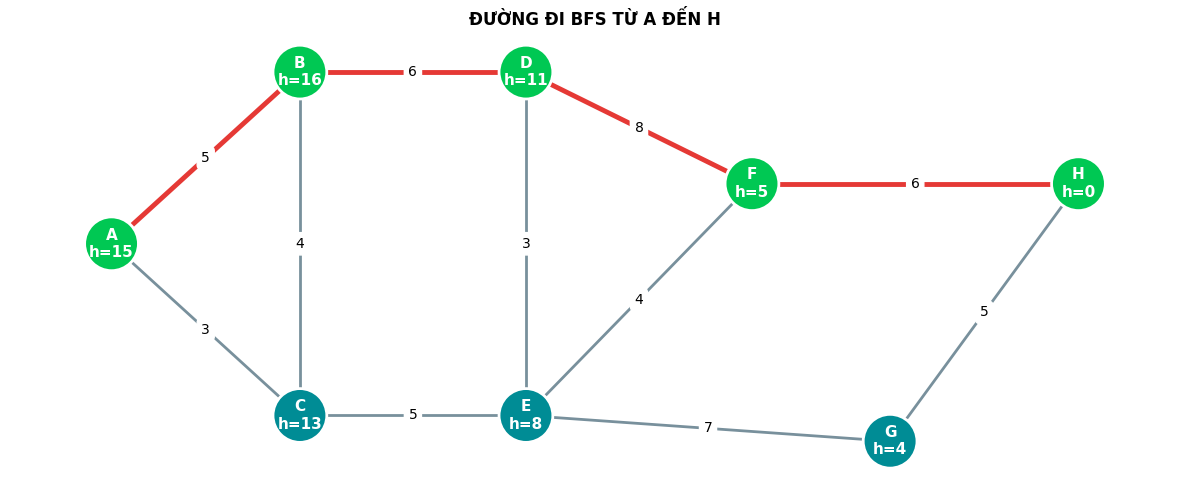

Đường đi BFS: A → B → D → F → H
Số cạnh: 4
Tổng trọng số (BFS không tối ưu trọng số): 25


In [27]:
# @title
fig, ax = plt.subplots(figsize=(12, 5))
draw_graph(ax, visited=set(path), path=path,
           title='ĐƯỜNG ĐI BFS TỪ A ĐẾN H')
plt.tight_layout()
plt.show()
print('Đường đi BFS:', ' → '.join(path))
print('Số cạnh:', len(path) - 1)
print('Tổng trọng số (BFS không tối ưu trọng số):',
      sum(G[u][v]['weight'] for u, v in zip(path, path[1:])))

Phần này vẽ lại đồ thị sau khi BFS tìm được đích. Các đỉnh nằm trên đường đi và các cạnh nối chúng được làm nổi bật. Bên dưới hình, chương trình in đường đi, số cạnh và tổng trọng số của đường đó. BFS tìm đường có ít cạnh nhất; nó không chọn đường dựa trên tổng trọng số cạnh

In [28]:
# @title
# Tạo trạng thái bắt đầu và các trạng thái sau từng lần lấy đỉnh khỏi hàng đợi
simulation_steps = [{
    'current': None, 'queue': ['A'], 'visited': {'A'}, 'parent': {'A': None},
    'new_nodes': [], 'message': 'Khởi tạo: đưa A vào hàng đợi.'
}]
queue = deque(['A'])
visited_sim = {'A'}
parent_sim = {'A': None}

while queue:
    current = queue.popleft()
    new_nodes = []
    if current != 'H':
        for neighbor in adjacency[current]:
            if neighbor not in visited_sim:
                visited_sim.add(neighbor)
                parent_sim[neighbor] = current
                queue.append(neighbor)
                new_nodes.append(neighbor)
    simulation_steps.append({
        'current': current, 'queue': list(queue), 'visited': set(visited_sim),
        'parent': dict(parent_sim), 'new_nodes': new_nodes,
        'message': f"Xét {current}. Đỉnh mới: {new_nodes or 'không có'}."
    })
    if current == 'H':
        break

final_path = []
node = 'H'
while node is not None and node in parent_sim:
    final_path.append(node)
    node = parent_sim[node]
final_path.reverse()

step_index = 0
btn_prev = widgets.Button(description='◀ Bước trước', layout=widgets.Layout(width='125px'))
btn_next = widgets.Button(description='Bước tiếp ▶', button_style='primary', layout=widgets.Layout(width='125px'))
btn_play = widgets.Button(description='▶ Chạy tự động', button_style='success', layout=widgets.Layout(width='145px'))
btn_reset = widgets.Button(description='↺ Đặt lại', button_style='warning', layout=widgets.Layout(width='110px'))
step_slider = widgets.IntSlider(value=0, min=0, max=len(simulation_steps)-1, step=1,
                                description='Bước:', continuous_update=False,
                                layout=widgets.Layout(width='95%'))
output = widgets.Output()

_busy = False
def show_step(index):
    global step_index, _busy
    if _busy:
        return
    _busy = True
    try:
        step_index = max(0, min(index, len(simulation_steps)-1))
        s = simulation_steps[step_index]
        with output:
            clear_output(wait=True)
            fig, ax = plt.subplots(figsize=(12, 5))
            found = s['current'] == 'H'
            draw_graph(ax, current=s['current'], visited=s['visited'], queue=s['queue'],
                       path=final_path if found else [],
                       title=f"BFS - Bước {step_index}/{len(simulation_steps)-1}")
            plt.tight_layout()
            plt.show()
            plt.close(fig)
            print('MÔ TẢ:', s['message'])
            print('Đỉnh đang xét:', s['current'] if s['current'] else 'Chưa xét')
            print('Hàng đợi:', s['queue'])
            print('Đã phát hiện:', sorted(s['visited']))
            print('Đỉnh mới:', s['new_nodes'])
            if found:
                print('ĐÃ TÌM THẤY H!')
                print('Đường đi:', ' → '.join(final_path))
        if step_slider.value != step_index:
            step_slider.value = step_index
    finally:
        _busy = False

def on_prev(_): show_step(step_index - 1)
def on_next(_): show_step(step_index + 1)
def on_reset(_): show_step(0)
def on_slider_change(change):
    if change['name'] == 'value' and not _busy:
        show_step(change['new'])

btn_prev.on_click(on_prev)
btn_next.on_click(on_next)
btn_reset.on_click(on_reset)
step_slider.observe(on_slider_change, names='value')

async def auto_play(_):
    import asyncio
    btn_play.disabled = True
    try:
        for i in range(step_index + 1, len(simulation_steps)):
            show_step(i)
            await asyncio.sleep(1.0)
    finally:
        btn_play.disabled = False
btn_play.on_click(auto_play)

display(widgets.VBox([
    widgets.HTML('<h3>Mô phỏng BFS: A → H</h3><p>Cam: đang xét | Xanh nhạt: đã phát hiện | Vàng: đang chờ | Xanh lá: đường đi cuối cùng. Trọng số cạnh được ghi trên hình.</p>'),
    widgets.HBox([btn_prev, btn_next, btn_play, btn_reset]), step_slider, output
]))
show_step(0)

# Mục mới

Phần này tạo giao diện để xem từng trạng thái BFS. Các nút cho phép lùi, tiến, chạy tự động hoặc quay lại bước đầu; thanh trượt cho phép chọn trực tiếp một bước. Khi chọn bước, chương trình vẽ lại đồ thị và hiển thị hàng đợi cùng các đỉnh đã phát hiện. Trạng thái khởi tạo được thêm vào để có thể xem đồ thị trước khi xét đỉnh nào.

In [29]:
# @title
def dfs_with_steps(graph, start, goal):
    if start not in graph or goal not in graph:
        raise ValueError('Đỉnh bắt đầu hoặc đích không có trong đồ thị.')
    stack = [start]
    visited = {start}
    parent = {start: None}
    steps = []

    while stack:
        current = stack.pop()
        newly_discovered = []
        if current != goal:
            for neighbor in reversed(graph[current]):
                if neighbor not in visited:
                    visited.add(neighbor)
                    parent[neighbor] = current
                    stack.append(neighbor)
                    newly_discovered.append(neighbor)
            newly_discovered.reverse()

        steps.append({
            'current': current,
            'queue': list(stack),  # danh sách này chính là ngăn xếp còn lại
            'visited': set(visited),
            'parent': dict(parent),
            'newly_discovered': newly_discovered,
            'found': current == goal
        })
        if current == goal:
            break

    path = []
    if goal in parent:
        node = goal
        while node is not None:
            path.append(node)
            node = parent[node]
        path.reverse()
    return path, steps

start_node, goal_node = 'A', 'H'
dfs_path, dfs_steps = dfs_with_steps(adjacency, start_node, goal_node)
print('Đỉnh bắt đầu:', start_node)
print('Đỉnh đích:', goal_node)
print('Số bước xử lý DFS:', len(dfs_steps))
print('Đường đi tìm được (DFS):', ' → '.join(dfs_path))
print('Số cạnh của đường đi:', len(dfs_path) - 1)
print('Tổng trọng số đường đi:', sum(G[u][v]['weight'] for u, v in zip(dfs_path, dfs_path[1:])))

Đỉnh bắt đầu: A
Đỉnh đích: H
Số bước xử lý DFS: 6
Đường đi tìm được (DFS): A → B → D → E → G → H
Số cạnh của đường đi: 5
Tổng trọng số đường đi: 26


DFS dùng ngăn xếp thay cho hàng đợi. Vì ngăn xếp hoạt động theo nguyên tắc vào sau, ra trước, thuật toán lấy đỉnh được thêm gần nhất để xét tiếp. Danh sách đỉnh kề được duyệt theo thứ tự ngược khi thêm vào ngăn xếp, nhằm giữ thứ tự xét giống thứ tự các đỉnh trong dữ liệu. Chương trình lưu lại từng trạng thái, ghi cha cho các đỉnh được phát hiện rồi lần ngược từ H để khôi phục đường đi.

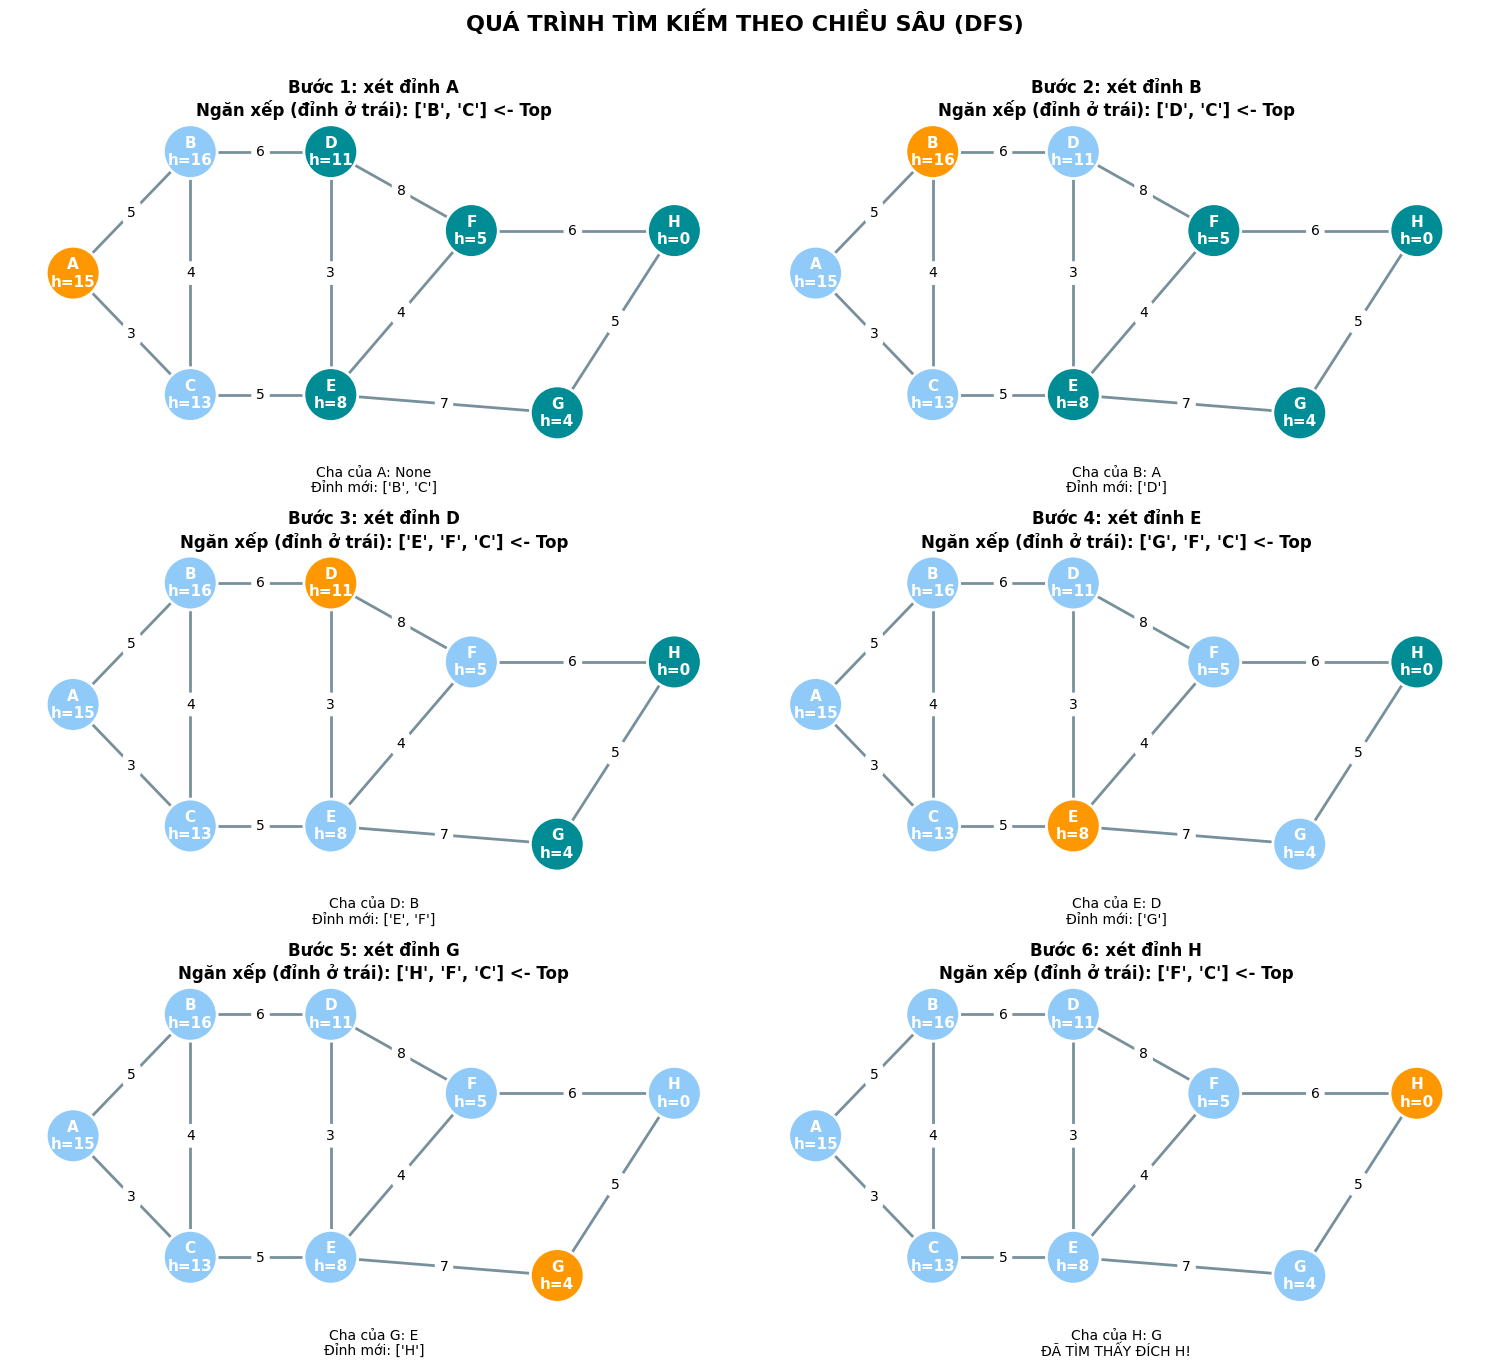

In [30]:
# @title
n_steps = len(dfs_steps)
ncols = 2
nrows = (n_steps + ncols - 1) // ncols
fig, axes = plt.subplots(nrows, ncols, figsize=(15, 4.5 * nrows))
axes = axes.flatten()

for i, step in enumerate(dfs_steps):
    current = step['current']
    stack_now = step['queue']
    stack_display = list(reversed(stack_now))
    title = (f"Bước {i + 1}: xét đỉnh {current}\n"
             f"Ngăn xếp (đỉnh ở trái): {stack_display} <- Top")
    draw_graph(axes[i], current=current, visited=step['visited'],
               queue=stack_now, title=title)
    info = f"Cha của {current}: {step['parent'].get(current)}"
    if step['newly_discovered']:
        info += f"\nĐỉnh mới: {step['newly_discovered']}"
    if step['found']:
        info += '\nĐÃ TÌM THẤY ĐÍCH H!'
    axes[i].text(0.5, -0.08, info, transform=axes[i].transAxes,
                 ha='center', va='top', fontsize=10)

for i in range(n_steps, len(axes)):
    axes[i].axis('off')
plt.suptitle('QUÁ TRÌNH TÌM KIẾM THEO CHIỀU SÂU (DFS)',
             fontsize=16, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

Mỗi hình tương ứng với một lượt DFS. Đồ thị cho thấy đỉnh đang xét, các đỉnh đã phát hiện và những đỉnh còn trong ngăn xếp. Ngăn xếp được hiển thị với đỉnh sẽ được lấy ra tiếp theo ở bên trái, giúp người xem hiểu rõ thứ tự xử lý. Chú thích bên dưới cho biết quan hệ cha và các đỉnh mới được thêm vào.

In [31]:
# @title
print('=' * 95)
print(f"{'BƯỚC':<8}{'ĐỈNH XÉT':<12}{'NGĂN XẾP (TOP TRÁI)':<38}{'ĐỈNH MỚI':<20}{'CHA'}")
print('=' * 95)
for i, step in enumerate(dfs_steps, start=1):
    stack_display = list(reversed(step['queue']))
    current = step['current']
    print(f"{i:<8}{current:<12}{str(stack_display):<38}"
          f"{str(step['newly_discovered']):<20}{step['parent'].get(current)}")
print('=' * 95)
print('Đường đi DFS:', ' → '.join(dfs_path))

BƯỚC    ĐỈNH XÉT    NGĂN XẾP (TOP TRÁI)                   ĐỈNH MỚI            CHA
1       A           ['B', 'C']                            ['B', 'C']          None
2       B           ['D', 'C']                            ['D']               A
3       D           ['E', 'F', 'C']                       ['E', 'F']          B
4       E           ['G', 'F', 'C']                       ['G']               D
5       G           ['H', 'F', 'C']                       ['H']               E
6       H           ['F', 'C']                            []                  G
Đường đi DFS: A → B → D → E → G → H


Bảng này liệt kê thứ tự DFS lấy các đỉnh ra khỏi ngăn xếp. Cột ngăn xếp được đảo thứ tự chỉ để hiển thị đỉnh trên cùng ở bên trái; dữ liệu ngăn xếp dùng cho thuật toán không bị thay đổi. Bảng cũng cho biết các đỉnh mới phát hiện và cha của đỉnh đang xét.

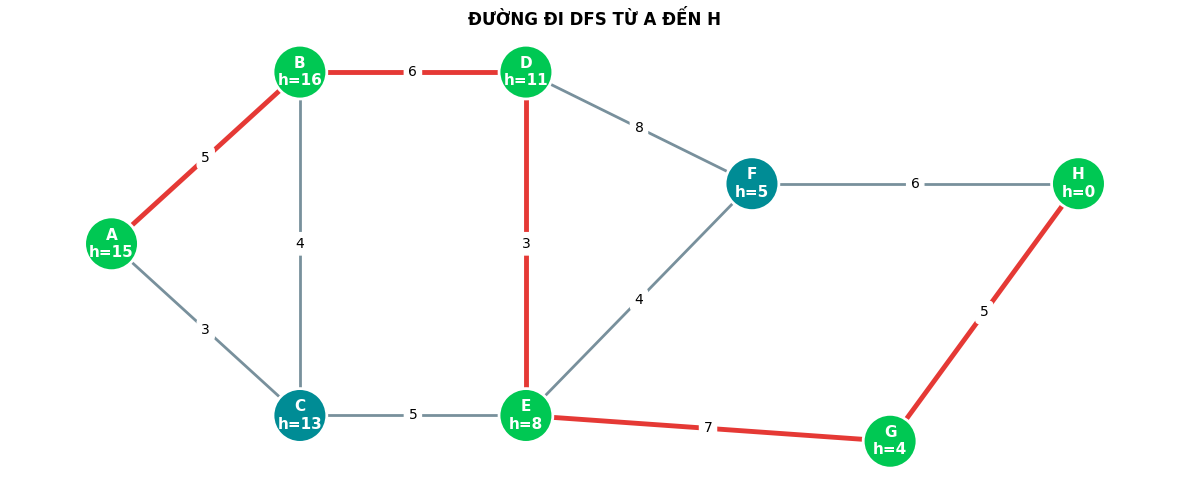

Đường đi DFS: A → B → D → E → G → H
Tổng số cạnh: 5
Tổng trọng số: 26


In [32]:
# @title
fig, ax = plt.subplots(figsize=(12, 5))
draw_graph(ax, visited=set(dfs_path), path=dfs_path,
           title='ĐƯỜNG ĐI DFS TỪ A ĐẾN H')
plt.tight_layout()
plt.show()
print('Đường đi DFS:', ' → '.join(dfs_path))
print('Tổng số cạnh:', len(dfs_path) - 1)
print('Tổng trọng số:', sum(G[u][v]['weight'] for u, v in zip(dfs_path, dfs_path[1:])))

Phần này tô nổi bật đường DFS tìm được từ A đến H trên đồ thị. Chương trình cũng in số cạnh và tổng trọng số của đường đi. DFS đi sâu theo nhánh và dừng khi gặp đích, nên đường tìm được có thể không phải đường có ít cạnh nhất hoặc tổng trọng số thấp nhất.

In [33]:
# @title
# Dùng lại các bước đã ghi ở P7; thêm trạng thái khởi tạo để mô phỏng nút bấm.
dfs_simulation = [{
    'current': None, 'queue': ['A'], 'visited': {'A'}, 'parent': {'A': None},
    'newly_discovered': [], 'found': False,
    'message': 'Khởi tạo: đưa A vào ngăn xếp.'
}]
for s in dfs_steps:
    dfs_simulation.append({**s, 'message':
        f"Xét {s['current']}. Đỉnh mới: {s['newly_discovered'] or 'không có'}."})

dfs_index = 0
dfs_busy = False
dfs_prev = widgets.Button(description='◀ Bước trước', layout=widgets.Layout(width='125px'))
dfs_next = widgets.Button(description='Bước tiếp ▶', button_style='primary', layout=widgets.Layout(width='125px'))
dfs_play = widgets.Button(description='▶ Chạy tự động', button_style='success', layout=widgets.Layout(width='145px'))
dfs_reset = widgets.Button(description='↺ Đặt lại', button_style='warning', layout=widgets.Layout(width='110px'))
dfs_slider = widgets.IntSlider(value=0, min=0, max=len(dfs_simulation)-1, step=1,
                                description='Bước:', continuous_update=False,
                                layout=widgets.Layout(width='95%'))
dfs_output = widgets.Output()

def show_dfs_step(index):
    global dfs_index, dfs_busy
    if dfs_busy: return
    dfs_busy = True
    try:
        dfs_index = max(0, min(index, len(dfs_simulation)-1))
        s = dfs_simulation[dfs_index]
        stack_display = list(reversed(s['queue']))
        with dfs_output:
            clear_output(wait=True)
            fig, ax = plt.subplots(figsize=(12, 5))
            draw_graph(ax, current=s['current'], visited=s['visited'], queue=s['queue'],
                       path=dfs_path if s['found'] else [],
                       title=f"DFS - Bước {dfs_index}/{len(dfs_simulation)-1}")
            plt.tight_layout(); plt.show(); plt.close(fig)
            print('MÔ TẢ:', s['message'])
            print('Đỉnh đang xét:', s['current'] if s['current'] else 'Chưa xét')
            print('Ngăn xếp (đỉnh trái là Top):', stack_display)
            print('Đã phát hiện:', sorted(s['visited']))
            print('Đỉnh mới:', s['newly_discovered'])
            if s['found']:
                print('ĐÃ TÌM THẤY H! Đường đi:', ' → '.join(dfs_path))
        if dfs_slider.value != dfs_index: dfs_slider.value = dfs_index
    finally:
        dfs_busy = False

def dfs_on_slider(change):
    if change['name'] == 'value' and not dfs_busy: show_dfs_step(change['new'])
def dfs_on_prev(_): show_dfs_step(dfs_index - 1)
def dfs_on_next(_): show_dfs_step(dfs_index + 1)
def dfs_on_reset(_): show_dfs_step(0)
async def dfs_auto_play(_):
    import asyncio
    dfs_play.disabled = True
    try:
        for i in range(dfs_index + 1, len(dfs_simulation)):
            show_dfs_step(i)
            await asyncio.sleep(1.0)
    finally:
        dfs_play.disabled = False

dfs_prev.on_click(dfs_on_prev); dfs_next.on_click(dfs_on_next)
dfs_reset.on_click(dfs_on_reset); dfs_play.on_click(dfs_auto_play)
dfs_slider.observe(dfs_on_slider, names='value')
display(widgets.VBox([
    widgets.HTML('<h3>Mô phỏng DFS: A → H</h3><p>Cam: đang xét | Xanh nhạt: đã phát hiện | Vàng: trong ngăn xếp | Xanh lá: đường đi cuối cùng.</p>'),
    widgets.HBox([dfs_prev, dfs_next, dfs_play, dfs_reset]), dfs_slider, dfs_output
]))
show_dfs_step(0)

Giao diện này cho phép xem từng bước DFS tương tự phần mô phỏng BFS. Trạng thái khởi tạo cho thấy A nằm trong ngăn xếp trước khi bắt đầu tìm kiếm. Khi chuyển bước, hình vẽ và phần thông tin bên dưới cập nhật ngăn xếp, các đỉnh đã phát hiện và đỉnh mới được thêm vào. Khi thuật toán gặp H, giao diện hiển thị đường đi cuối cùng

In [34]:
# @title
import heapq

def astar_with_steps(graph, edge_list, h, start, goal):
    if start not in graph or goal not in graph:
        raise ValueError('Đỉnh bắt đầu hoặc đích không có trong đồ thị.')
    weights = {node: {} for node in graph}
    for u, v, w in edge_list:
        weights[u][v] = w
        weights[v][u] = w

    counter = 0
    heap = [(h[start], 0, counter, start)]  # (f, g, thứ tự thêm, đỉnh)
    open_nodes = {start}
    closed = set()
    parent = {start: None}
    g_score = {start: 0}
    steps = []

    while heap:
        f, g_cost, _, current = heapq.heappop(heap)
        if current in closed or g_cost != g_score.get(current):
            continue
        open_nodes.discard(current)
        closed.add(current)
        newly_discovered = []

        if current != goal:
            for neighbor in graph[current]:
                tentative_g = g_cost + weights[current][neighbor]
                if tentative_g < g_score.get(neighbor, float('inf')):
                    is_new = neighbor not in g_score
                    g_score[neighbor] = tentative_g
                    parent[neighbor] = current
                    counter += 1
                    heapq.heappush(heap, (tentative_g + h[neighbor], tentative_g, counter, neighbor))
                    open_nodes.add(neighbor)
                    if is_new:
                        newly_discovered.append(neighbor)

        open_display = sorted(open_nodes, key=lambda n: (g_score[n] + h[n], n))
        steps.append({
            'current': current, 'open': open_display, 'visited': set(closed),
            'parent': dict(parent), 'g_score': dict(g_score),
            'newly_discovered': newly_discovered, 'found': current == goal,
            'g': g_cost, 'h': h[current], 'f': g_cost + h[current]
        })
        if current == goal:
            break

    path = []
    if goal in parent:
        node = goal
        while node is not None:
            path.append(node)
            node = parent[node]
        path.reverse()
    return path, g_score.get(goal, float('inf')), steps

astar_path, astar_cost, astar_steps = astar_with_steps(
    adjacency, edges, heuristic, 'A', 'H'
)
print('Đỉnh bắt đầu: A | Đỉnh đích: H')
print('Số bước xử lý A*:', len(astar_steps))
print('Đường đi A*:', ' → '.join(astar_path))
print('Tổng trọng số:', astar_cost)

Đỉnh bắt đầu: A | Đỉnh đích: H
Số bước xử lý A*: 5
Đường đi A*: A → C → E → F → H
Tổng trọng số: 18


A* dùng tổng g + h để chọn đỉnh tiếp theo. g là tổng trọng số từ A đến đỉnh hiện tại; h là giá trị heuristic ghi trong hình. Thuật toán ưu tiên đỉnh có tổng này nhỏ hơn trong danh sách chờ. Khi phát hiện một đường đi có chi phí thấp hơn đến một đỉnh, chương trình cập nhật chi phí và cha của đỉnh đó. Mỗi lượt xét được lưu lại, gồm đỉnh hiện tại, các giá trị g, h, f, danh sách chờ và thông tin cha

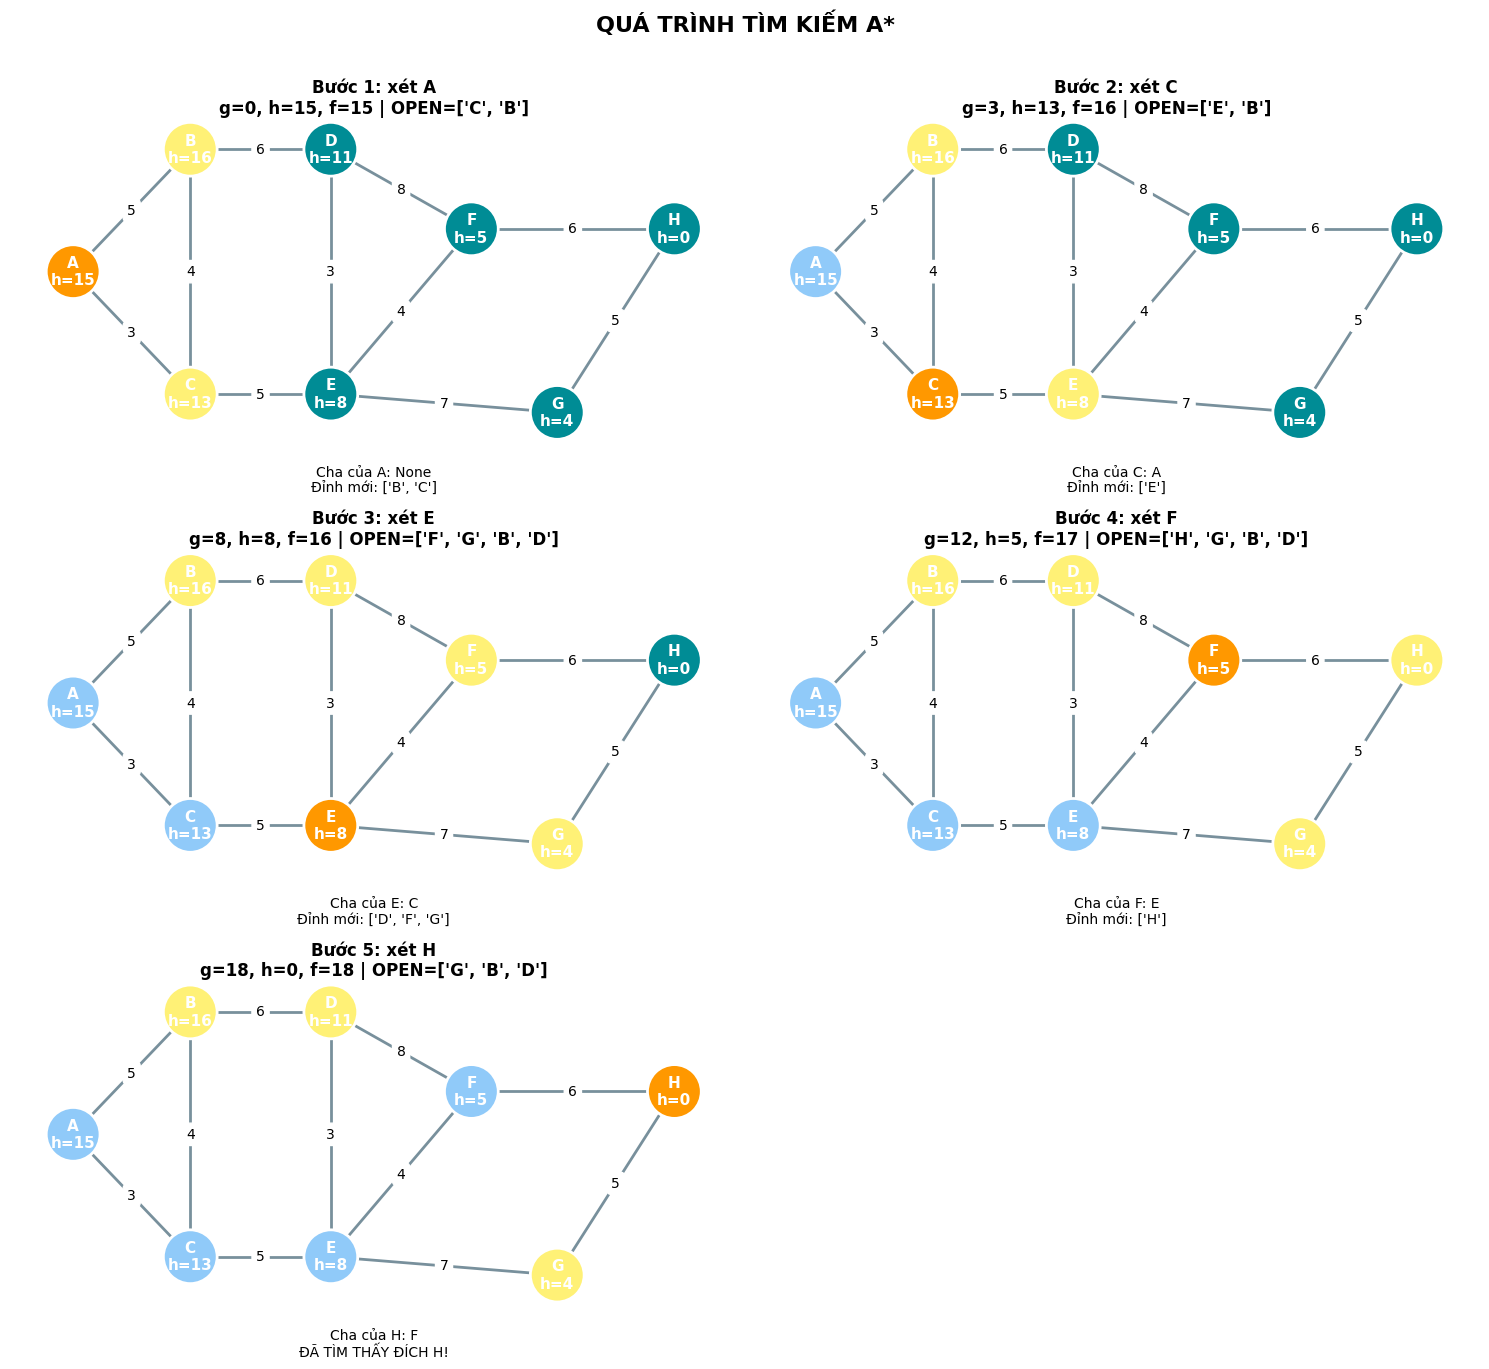

In [35]:
# @title
n_steps = len(astar_steps)
ncols = 2
nrows = (n_steps + ncols - 1) // ncols
fig, axes = plt.subplots(nrows, ncols, figsize=(15, 4.5 * nrows))
axes = axes.flatten()
for i, step in enumerate(astar_steps):
    current = step['current']
    title = (f"Bước {i + 1}: xét {current}\n"
             f"g={step['g']}, h={step['h']}, f={step['f']} | OPEN={step['open']}")
    draw_graph(axes[i], current=current, visited=step['visited'],
               queue=step['open'], title=title)
    info = f"Cha của {current}: {step['parent'].get(current)}"
    if step['newly_discovered']:
        info += f"\nĐỉnh mới: {step['newly_discovered']}"
    if step['found']:
        info += '\nĐÃ TÌM THẤY ĐÍCH H!'
    axes[i].text(0.5, -0.08, info, transform=axes[i].transAxes,
                 ha='center', va='top', fontsize=10)
for i in range(n_steps, len(axes)):
    axes[i].axis('off')
plt.suptitle('QUÁ TRÌNH TÌM KIẾM A*', fontsize=16, fontweight='bold', y=1.01)
plt.tight_layout(); plt.show()

Mỗi hình thể hiện một lượt A*. Tiêu đề cho biết đỉnh được xét, các giá trị g, h, f và những đỉnh còn trong danh sách chờ. Màu sắc trên đồ thị giúp phân biệt đỉnh hiện tại, các đỉnh đã mở rộng và các đỉnh đang chờ. Phần chú thích ghi quan hệ cha và thông báo khi thuật toán đến H

In [36]:
# @title
print('=' * 104)
print(f"{'BƯỚC':<7}{'ĐỈNH XÉT':<12}{'g':<7}{'h':<7}{'f=g+h':<9}{'OPEN sau xử lý':<30}{'ĐỈNH MỚI'}")
print('=' * 104)
for i, step in enumerate(astar_steps, start=1):
    print(f"{i:<7}{step['current']:<12}{step['g']:<7}{step['h']:<7}{step['f']:<9}"
          f"{str(step['open']):<30}{step['newly_discovered']}")
print('=' * 104)
print('Đường đi A*:', ' → '.join(astar_path))
print('Tổng trọng số:', astar_cost)

BƯỚC   ĐỈNH XÉT    g      h      f=g+h    OPEN sau xử lý                ĐỈNH MỚI
1      A           0      15     15       ['C', 'B']                    ['B', 'C']
2      C           3      13     16       ['E', 'B']                    ['E']
3      E           8      8      16       ['F', 'G', 'B', 'D']          ['D', 'F', 'G']
4      F           12     5      17       ['H', 'G', 'B', 'D']          ['H']
5      H           18     0      18       ['G', 'B', 'D']               []
Đường đi A*: A → C → E → F → H
Tổng trọng số: 18


Bảng này ghi lại các quyết định của A*. Mỗi dòng có đỉnh được xét, chi phí đã đi từ A, giá trị heuristic, tổng f, danh sách chờ sau khi xét và các đỉnh mới phát hiện. Có thể dùng cột f để theo dõi vì sao A* chọn một đỉnh trước các đỉnh khác.

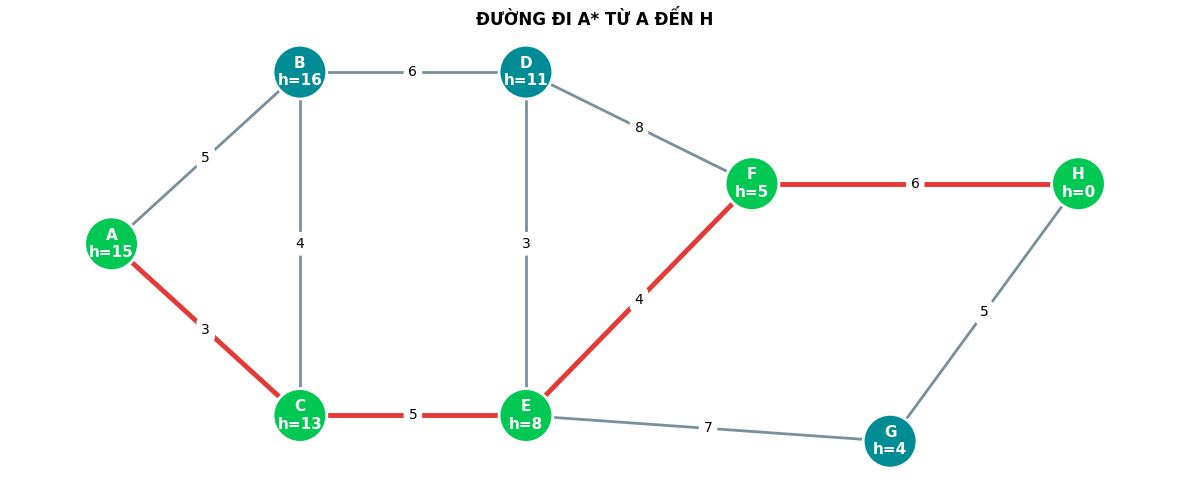

Đường đi tối ưu theo trọng số: A → C → E → F → H
Tổng trọng số: 18
Số cạnh: 4


In [37]:
# @title
fig, ax = plt.subplots(figsize=(12, 5))
draw_graph(ax, visited={s['current'] for s in astar_steps}, path=astar_path,
           title='ĐƯỜNG ĐI A* TỪ A ĐẾN H')
plt.tight_layout(); plt.show()
print('Đường đi tối ưu theo trọng số:', ' → '.join(astar_path))
print('Tổng trọng số:', astar_cost)
print('Số cạnh:', len(astar_path) - 1)

Phần này vẽ đường đi A* tìm được và làm nổi bật các đỉnh cùng cạnh thuộc đường đó. Kết quả in bên dưới gồm chuỗi đỉnh, tổng trọng số và số cạnh. Với dữ liệu trong hình, đường đi A* là A → C → E → F → H, có tổng trọng số 18.

In [38]:
# @title
astar_simulation = [{
    'current': None, 'open': ['A'], 'visited': set(), 'parent': {'A': None},
    'g_score': {'A': 0}, 'newly_discovered': [], 'found': False,
    'g': 0, 'h': heuristic['A'], 'f': heuristic['A'],
    'message': 'Khởi tạo: đưa A vào OPEN với f(A)=g(A)+h(A).'
}]
for s in astar_steps:
    astar_simulation.append({**s, 'message':
        f"Xét {s['current']}: g={s['g']}, h={s['h']}, f={s['f']}. "
        f"Đỉnh mới: {s['newly_discovered'] or 'không có'}."})

astar_index = 0
astar_busy = False
astar_prev = widgets.Button(description='◀ Bước trước', layout=widgets.Layout(width='125px'))
astar_next = widgets.Button(description='Bước tiếp ▶', button_style='primary', layout=widgets.Layout(width='125px'))
astar_play = widgets.Button(description='▶ Chạy tự động', button_style='success', layout=widgets.Layout(width='145px'))
astar_reset = widgets.Button(description='↺ Đặt lại', button_style='warning', layout=widgets.Layout(width='110px'))
astar_slider = widgets.IntSlider(value=0, min=0, max=len(astar_simulation)-1, step=1,
                                  description='Bước:', continuous_update=False,
                                  layout=widgets.Layout(width='95%'))
astar_output = widgets.Output()

def show_astar_step(index):
    global astar_index, astar_busy
    if astar_busy: return
    astar_busy = True
    try:
        astar_index = max(0, min(index, len(astar_simulation)-1))
        s = astar_simulation[astar_index]
        with astar_output:
            clear_output(wait=True)
            fig, ax = plt.subplots(figsize=(12, 5))
            draw_graph(ax, current=s['current'], visited=s['visited'], queue=s['open'],
                       path=astar_path if s['found'] else [],
                       title=f"A* - Bước {astar_index}/{len(astar_simulation)-1}")
            plt.tight_layout(); plt.show(); plt.close(fig)
            print('MÔ TẢ:', s['message'])
            print('Đỉnh đang xét:', s['current'] if s['current'] else 'Chưa xét')
            print('OPEN (ưu tiên f nhỏ):', s['open'])
            print('Đã mở rộng:', sorted(s['visited']))
            print('g-score:', s['g_score'])
            if s['found']:
                print('ĐÃ TÌM THẤY H!')
                print('Đường đi:', ' → '.join(astar_path))
                print('Tổng trọng số:', astar_cost)
        if astar_slider.value != astar_index: astar_slider.value = astar_index
    finally:
        astar_busy = False

def astar_on_slider(change):
    if change['name'] == 'value' and not astar_busy: show_astar_step(change['new'])
def astar_on_prev(_): show_astar_step(astar_index - 1)
def astar_on_next(_): show_astar_step(astar_index + 1)
def astar_on_reset(_): show_astar_step(0)
async def astar_auto_play(_):
    import asyncio
    astar_play.disabled = True
    try:
        for i in range(astar_index + 1, len(astar_simulation)):
            show_astar_step(i)
            await asyncio.sleep(1.0)
    finally:
        astar_play.disabled = False

astar_prev.on_click(astar_on_prev); astar_next.on_click(astar_on_next)
astar_reset.on_click(astar_on_reset); astar_play.on_click(astar_auto_play)
astar_slider.observe(astar_on_slider, names='value')
display(widgets.VBox([
    widgets.HTML('<h3>Mô phỏng A*: A → H</h3><p>Cam: đang xét | Xanh nhạt: đã mở rộng | Vàng: trong OPEN | Xanh lá: đường đi cuối cùng.</p>'),
    widgets.HBox([astar_prev, astar_next, astar_play, astar_reset]), astar_slider, astar_output
]))
show_astar_step(0)

Giao diện cho phép xem từng bước A* bằng nút lùi, tiến, chạy tự động, đặt lại và thanh trượt. Mỗi trạng thái hiển thị đỉnh đang xét, các đỉnh trong danh sách chờ, những đỉnh đã mở rộng và chi phí tốt nhất hiện biết đến từng đỉnh. Khi thuật toán gặp H, giao diện làm nổi bật đường đi cuối cùng và tổng trọng số của nó.

**ĐỒ Thị Có Hướng**


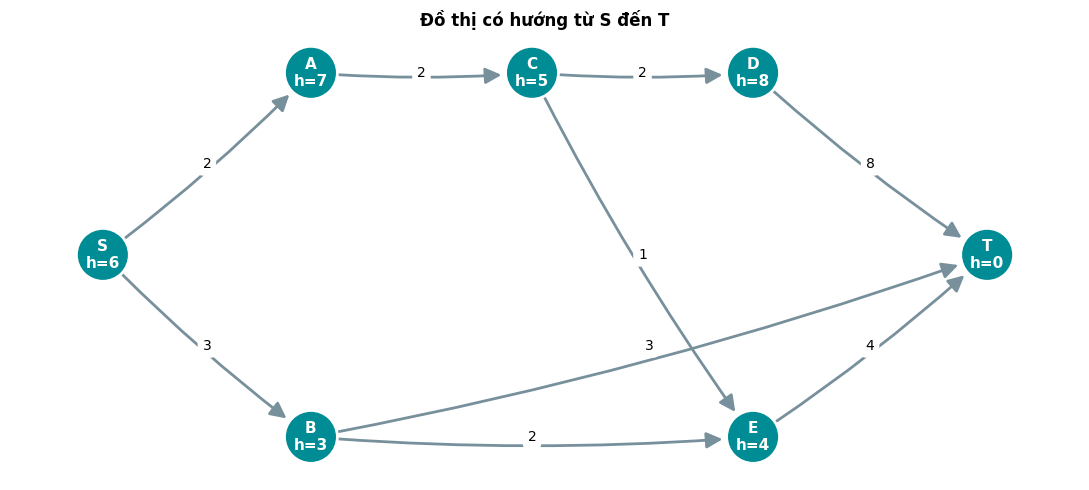

In [39]:
# @title
import networkx as nx
import matplotlib.pyplot as plt
from collections import deque
from IPython.display import display, clear_output
import ipywidgets as widgets

# Cạnh có hướng: (đỉnh nguồn, đỉnh đích, chi phí)
edges = [
    ('S', 'A', 2), ('S', 'B', 3),
    ('A', 'C', 2), ('B', 'T', 3), ('B', 'E', 2),
    ('C', 'D', 2), ('C', 'E', 1),
    ('D', 'T', 8), ('E', 'T', 4),
]
heuristic = {'S': 6, 'A': 7, 'B': 3, 'C': 5, 'D': 8, 'E': 4, 'T': 0}
adjacency = {node: [] for node in heuristic}
for u, v, w in edges:
    adjacency[u].append(v)  # chỉ thêm chiều u -> v

G = nx.DiGraph()
G.add_weighted_edges_from(edges)
pos = {
    'S': (0, 1), 'A': (1.6, 2.2), 'B': (1.6, -0.2),
    'C': (3.3, 2.2), 'D': (5.0, 2.2), 'E': (5.0, -0.2), 'T': (6.8, 1)
}

def draw_graph(ax, current=None, visited=None, queue=None, path=None,
               title='Đồ thị có hướng'):
    visited = set() if visited is None else set(visited)
    queue = [] if queue is None else list(queue)
    path = [] if path is None else list(path)
    path_edges = {(path[i], path[i+1]) for i in range(len(path)-1)}

    colors = []
    for node in G.nodes():
        if node == current: colors.append('#FF9800')
        elif node in path: colors.append('#00C853')
        elif node in visited: colors.append('#90CAF9')
        elif node in queue: colors.append('#FFF176')
        else: colors.append('#008C95')
    edge_colors = ['#E53935' if e in path_edges else '#78909C' for e in G.edges()]
    edge_widths = [3.5 if e in path_edges else 2 for e in G.edges()]
    nx.draw_networkx_edges(G, pos, ax=ax, edge_color=edge_colors, width=edge_widths,
                           arrows=True, arrowstyle='-|>', arrowsize=24, node_size=1450,
                           min_source_margin=18, min_target_margin=22,
                           connectionstyle='arc3,rad=0.04')
    nx.draw_networkx_nodes(G, pos, ax=ax, node_color=colors, node_size=1450,
                           edgecolors='white', linewidths=2)
    labels = {n: f'{n}\nh={heuristic[n]}' for n in G.nodes()}
    nx.draw_networkx_labels(G, pos, ax=ax, labels=labels, font_size=11,
                            font_weight='bold', font_color='white')
    nx.draw_networkx_edge_labels(G, pos, ax=ax,
                                 edge_labels={(u,v):w for u,v,w in edges},
                                 font_size=10, rotate=False, label_pos=0.5)
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.axis('off')

fig, ax = plt.subplots(figsize=(11, 5))
draw_graph(ax, title='Đồ thị có hướng từ S đến T')
plt.tight_layout()
plt.show()

Phần này chuẩn bị thư viện, dữ liệu đồ thị và hàm vẽ. Mỗi cạnh có đỉnh xuất phát, đỉnh đến và trọng số. Danh sách kề chỉ ghi các hướng được phép đi; nếu có cạnh từ S đến A thì không mặc nhiên được đi từ A về S. Giá trị heuristic được gán cho từng đỉnh. Hàm vẽ thể hiện hướng bằng mũi tên, trọng số trên cạnh và heuristic cạnh tên đỉnh.

In [40]:
# @title
def bfs_with_steps(graph, start, goal):
    if start not in graph or goal not in graph:
        raise ValueError('Điểm bắt đầu hoặc đích không có trong đồ thị.')
    queue = deque([start])
    visited = {start}
    parent = {start: None}
    steps = []
    while queue:
        current = queue.popleft()
        newly_discovered = []
        if current != goal:
            for neighbor in graph[current]:
                if neighbor not in visited:
                    visited.add(neighbor)
                    parent[neighbor] = current
                    queue.append(neighbor)
                    newly_discovered.append(neighbor)
        steps.append({'current':current, 'queue':list(queue), 'visited':set(visited),
                      'parent':dict(parent), 'newly_discovered':newly_discovered,
                      'found':current == goal})
        if current == goal: break
    path=[]
    if goal in parent:
        node=goal
        while node is not None:
            path.append(node); node=parent[node]
        path.reverse()
    return path, steps

def path_cost(path):
    weight={(u,v):w for u,v,w in edges}
    return sum(weight[(u,v)] for u,v in zip(path,path[1:])) if path else 0

start_node, goal_node = 'S', 'T'
bfs_path, bfs_steps = bfs_with_steps(adjacency, start_node, goal_node)
print('Đỉnh bắt đầu:', start_node)
print('Đỉnh đích:', goal_node)
print('Số bước xử lý:', len(bfs_steps))
print('Đường đi BFS:', ' → '.join(bfs_path))
print('Số cạnh:', len(bfs_path)-1)
print('Tổng trọng số đường BFS:', path_cost(bfs_path))

Đỉnh bắt đầu: S
Đỉnh đích: T
Số bước xử lý: 5
Đường đi BFS: S → B → T
Số cạnh: 2
Tổng trọng số đường BFS: 6


BFS bắt đầu tại S và dùng hàng đợi để xét các đỉnh theo thứ tự được phát hiện. Mỗi khi gặp một đỉnh mới, thuật toán ghi lại đỉnh cha của nó rồi đưa nó vào hàng đợi. Khi đến T, chương trình dừng và lần ngược thông tin cha để khôi phục đường đi. Các trạng thái trung gian được lưu lại để dùng ở những phần sau.

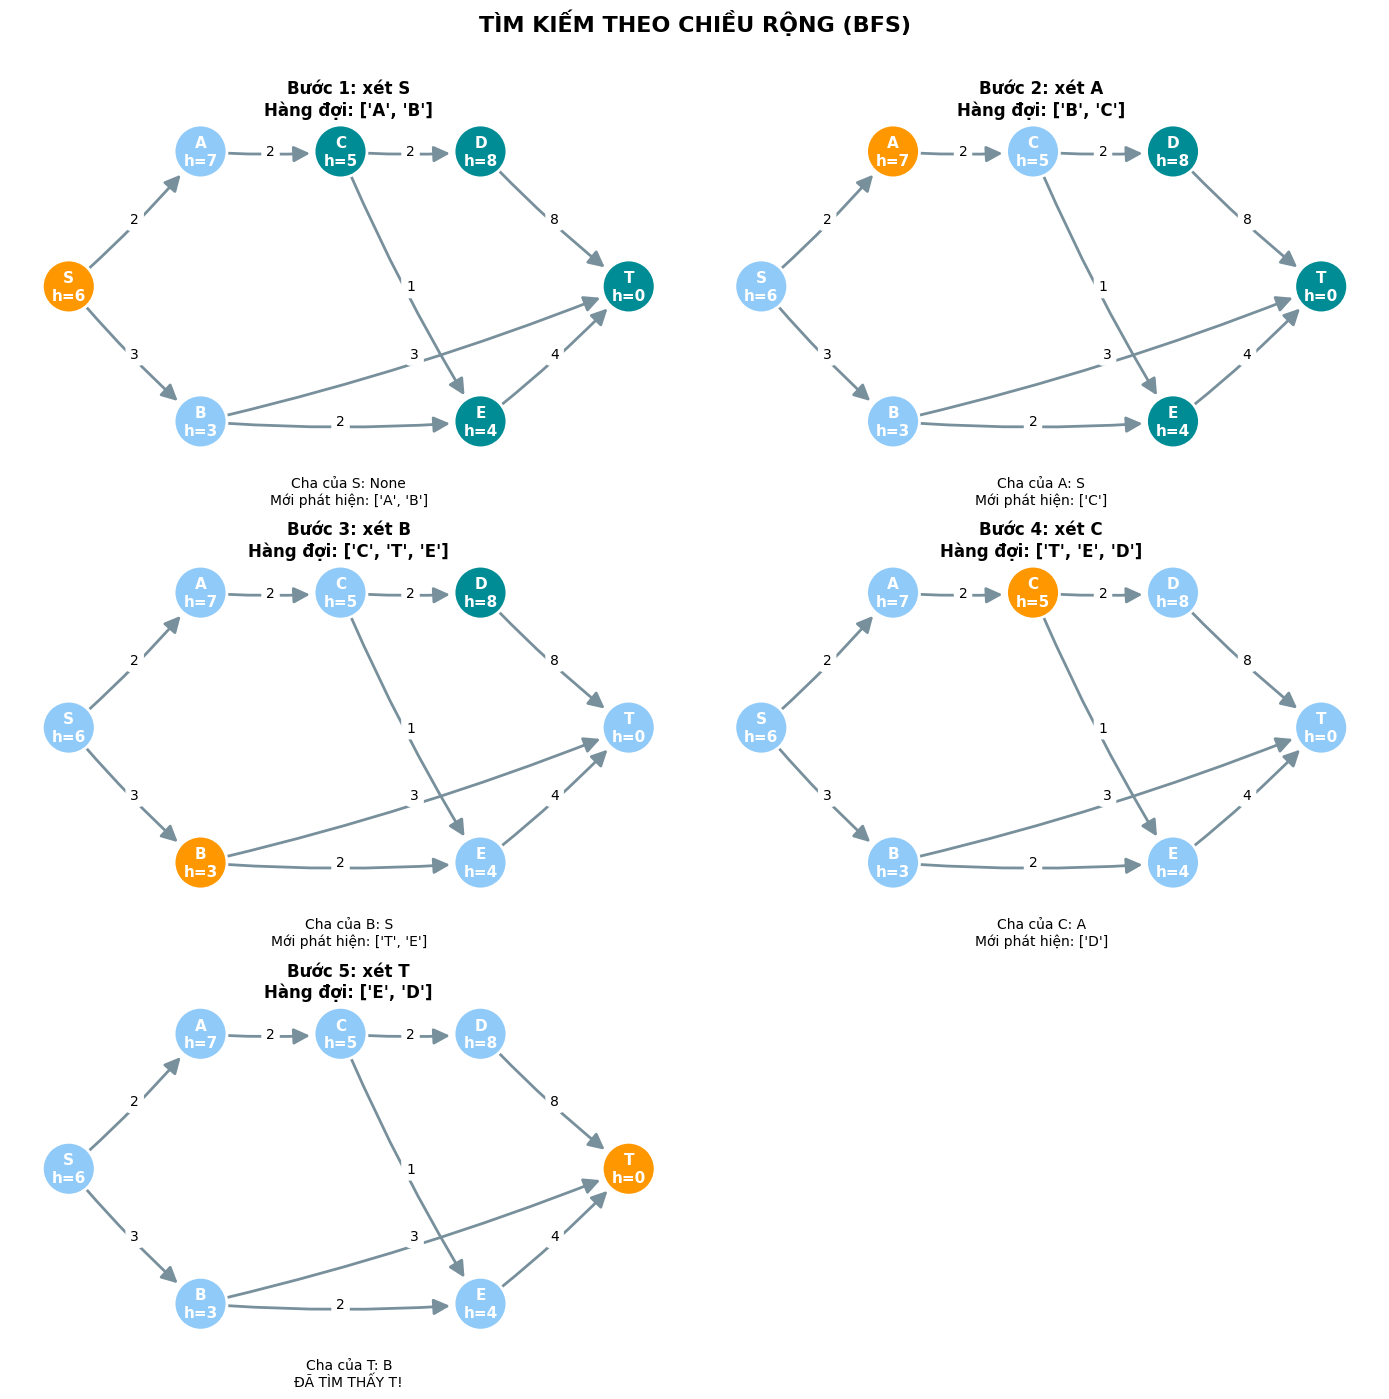

In [41]:
# @title
n_steps=len(bfs_steps); ncols=2; nrows=(n_steps+ncols-1)//ncols
fig,axes=plt.subplots(nrows,ncols,figsize=(14,4.6*nrows)); axes=axes.flatten()
for i,step in enumerate(bfs_steps):
    title=f"Bước {i+1}: xét {step['current']}\nHàng đợi: {step['queue']}"
    draw_graph(axes[i],current=step['current'],visited=step['visited'],
               queue=step['queue'],title=title)
    info=f"Cha của {step['current']}: {step['parent'].get(step['current'])}"
    if step['newly_discovered']: info+=f"\nMới phát hiện: {step['newly_discovered']}"
    if step['found']: info+='\nĐÃ TÌM THẤY T!'
    axes[i].text(.5,-.08,info,transform=axes[i].transAxes,ha='center',va='top',fontsize=10)
for i in range(n_steps,len(axes)): axes[i].axis('off')
plt.suptitle('TÌM KIẾM THEO CHIỀU RỘNG (BFS)',fontsize=16,fontweight='bold',y=1.01)
plt.tight_layout(); plt.show()

Phần này vẽ một hình cho mỗi lượt BFS. Hình cho biết đỉnh đang xét, các đỉnh đã được phát hiện và những đỉnh còn trong hàng đợi. Mũi tên giữ nguyên hướng của đồ thị, giúp theo dõi các bước di chuyển hợp lệ.

In [42]:
# @title
print('='*86)
print(f"{'BƯỚC':<8}{'ĐỈNH XÉT':<13}{'ĐỈNH MỚI':<20}{'HÀNG ĐỢI SAU XỬ LÝ':<28}{'CHA'}")
print('='*86)
for i,s in enumerate(bfs_steps,1):
    print(f"{i:<8}{s['current']:<13}{str(s['newly_discovered']):<20}"
          f"{str(s['queue']):<28}{s['parent'].get(s['current'])}")
print('='*86)
print('Đường đi BFS:', ' → '.join(bfs_path))

BƯỚC    ĐỈNH XÉT     ĐỈNH MỚI            HÀNG ĐỢI SAU XỬ LÝ          CHA
1       S            ['A', 'B']          ['A', 'B']                  None
2       A            ['C']               ['B', 'C']                  S
3       B            ['T', 'E']          ['C', 'T', 'E']             S
4       C            ['D']               ['T', 'E', 'D']             A
5       T            []                  ['E', 'D']                  B
Đường đi BFS: S → B → T


Bảng trình bày quá trình BFS bằng văn bản. Mỗi dòng ghi đỉnh đang xét, các đỉnh mới được phát hiện, hàng đợi sau lượt xử lý và đỉnh cha. Bảng này giúp đối chiếu thứ tự duyệt với hình minh họa ở P3.

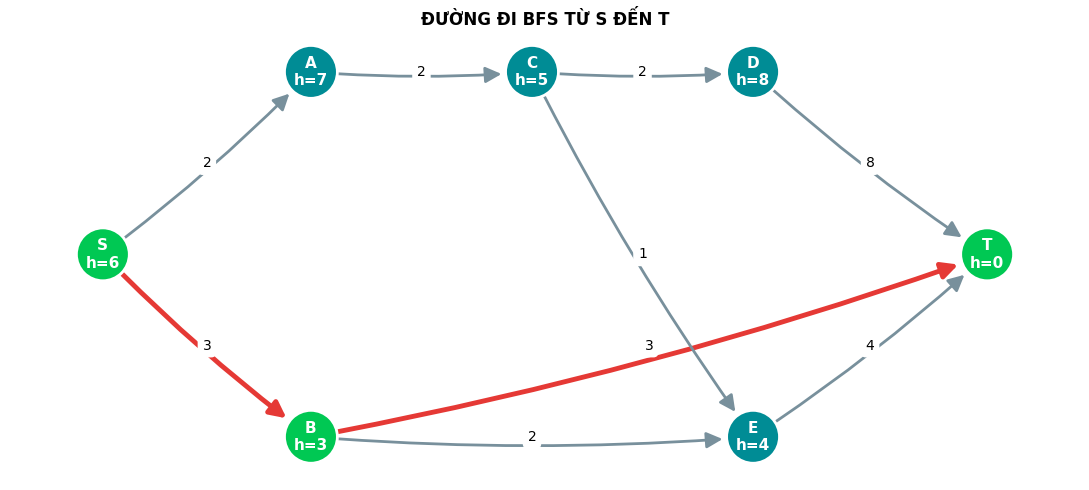

Đường đi BFS: S → B → T
Số cạnh: 2 | Tổng trọng số: 6


In [43]:
# @title
fig,ax=plt.subplots(figsize=(11,5))
draw_graph(ax,visited=set(bfs_path),path=bfs_path,title='ĐƯỜNG ĐI BFS TỪ S ĐẾN T')
plt.tight_layout(); plt.show()
print('Đường đi BFS:', ' → '.join(bfs_path))
print('Số cạnh:',len(bfs_path)-1,'| Tổng trọng số:',path_cost(bfs_path))

Phần này làm nổi bật đường BFS tìm được trên đồ thị, đồng thời in số cạnh và tổng trọng số của đường. BFS tìm đường có ít cạnh nhất theo thứ tự các đỉnh kề; thuật toán không chọn đường dựa trên tổng trọng số.

In [44]:
# @title
bfs_sim=[{'current':None,'queue':['S'],'visited':{'S'},'newly_discovered':[],
          'found':False,'message':'Khởi tạo: đưa S vào hàng đợi.'}]
for s in bfs_steps:
    bfs_sim.append({**s,'message':f"Xét {s['current']}; phát hiện mới: {s['newly_discovered'] or 'không có'}."})
bfs_i=0; bfs_busy=False
bfs_prev=widgets.Button(description='◀ Bước trước',layout=widgets.Layout(width='125px'))
bfs_next=widgets.Button(description='Bước tiếp ▶',button_style='primary',layout=widgets.Layout(width='125px'))
bfs_play=widgets.Button(description='▶ Chạy tự động',button_style='success',layout=widgets.Layout(width='145px'))
bfs_reset=widgets.Button(description='↺ Đặt lại',button_style='warning',layout=widgets.Layout(width='110px'))
bfs_slider=widgets.IntSlider(value=0,min=0,max=len(bfs_sim)-1,step=1,description='Bước:',continuous_update=False,layout=widgets.Layout(width='95%'))
bfs_output=widgets.Output()

def show_bfs(i):
    global bfs_i,bfs_busy
    if bfs_busy:return
    bfs_busy=True
    try:
        bfs_i=max(0,min(i,len(bfs_sim)-1)); s=bfs_sim[bfs_i]
        with bfs_output:
            clear_output(wait=True); fig,ax=plt.subplots(figsize=(11,5))
            draw_graph(ax,current=s['current'],visited=s['visited'],queue=s['queue'],
                       path=bfs_path if s['found'] else [],title=f"BFS - bước {bfs_i}/{len(bfs_sim)-1}")
            plt.tight_layout();plt.show();plt.close(fig)
            print(s['message']);print('Hàng đợi:',s['queue']);print('Đã phát hiện:',sorted(s['visited']))
            if s['found']:print('Đường đi:', ' → '.join(bfs_path),'| chi phí:',path_cost(bfs_path))
        if bfs_slider.value!=bfs_i:bfs_slider.value=bfs_i
    finally:bfs_busy=False

def bfs_slider_changed(ch):
    if ch['name']=='value' and not bfs_busy:show_bfs(ch['new'])
async def bfs_auto(_):
    import asyncio
    bfs_play.disabled=True
    try:
        for j in range(bfs_i+1,len(bfs_sim)):
            show_bfs(j);await asyncio.sleep(1)
    finally:bfs_play.disabled=False
bfs_prev.on_click(lambda _:show_bfs(bfs_i-1));bfs_next.on_click(lambda _:show_bfs(bfs_i+1))
bfs_reset.on_click(lambda _:show_bfs(0));bfs_play.on_click(bfs_auto)
bfs_slider.observe(bfs_slider_changed,names='value')
display(widgets.VBox([widgets.HTML('<h3>Mô phỏng BFS: S → T</h3><p>Mũi tên cho biết hướng đi được phép. Cam: hiện tại | xanh nhạt: đã phát hiện | vàng: đang chờ | xanh lá: đường đi.</p>'),widgets.HBox([bfs_prev,bfs_next,bfs_play,bfs_reset]),bfs_slider,bfs_output]))
show_bfs(0)

Các trạng thái BFS được đưa vào giao diện có nút lùi, tiến, chạy tự động, đặt lại và thanh trượt. Khi chọn một bước, đồ thị và thông tin hàng đợi được cập nhật tương ứng. Trạng thái khởi tạo cho phép xem hàng đợi trước khi BFS bắt đầu xử lý.

In [45]:
# @title
def dfs_with_steps(graph,start,goal):
    if start not in graph or goal not in graph:
        raise ValueError('Điểm bắt đầu hoặc đích không có trong đồ thị.')
    stack=[start]; visited={start}; parent={start:None}; steps=[]
    while stack:
        current=stack.pop(); newly_discovered=[]
        if current!=goal:
            # Đảo thứ tự để phần tử khai báo trước được lấy ra trước (LIFO)
            for neighbor in reversed(graph[current]):
                if neighbor not in visited:
                    visited.add(neighbor);parent[neighbor]=current
                    stack.append(neighbor);newly_discovered.append(neighbor)
            newly_discovered.reverse()
        steps.append({'current':current,'queue':list(stack),'visited':set(visited),
                      'parent':dict(parent),'newly_discovered':newly_discovered,
                      'found':current==goal})
        if current==goal:break
    path=[]
    if goal in parent:
        node=goal
        while node is not None:path.append(node);node=parent[node]
        path.reverse()
    return path,steps

dfs_path,dfs_steps=dfs_with_steps(adjacency,'S','T')
print('Đỉnh bắt đầu: S | Đỉnh đích: T')
print('Số bước xử lý DFS:',len(dfs_steps))
print('Đường đi DFS:', ' → '.join(dfs_path))
print('Số cạnh:',len(dfs_path)-1,'| Tổng trọng số:',path_cost(dfs_path))

Đỉnh bắt đầu: S | Đỉnh đích: T
Số bước xử lý DFS: 5
Đường đi DFS: S → A → C → D → T
Số cạnh: 4 | Tổng trọng số: 14


DFS dùng ngăn xếp để đi sâu theo từng nhánh. Các đỉnh kề được thêm theo thứ tự phù hợp để đỉnh đứng trước trong danh sách được xét trước. Thuật toán ghi lại các đỉnh đã phát hiện và quan hệ cha, rồi dừng khi đến T. Từ quan hệ cha, chương trình khôi phục đường đi từ S đến T.

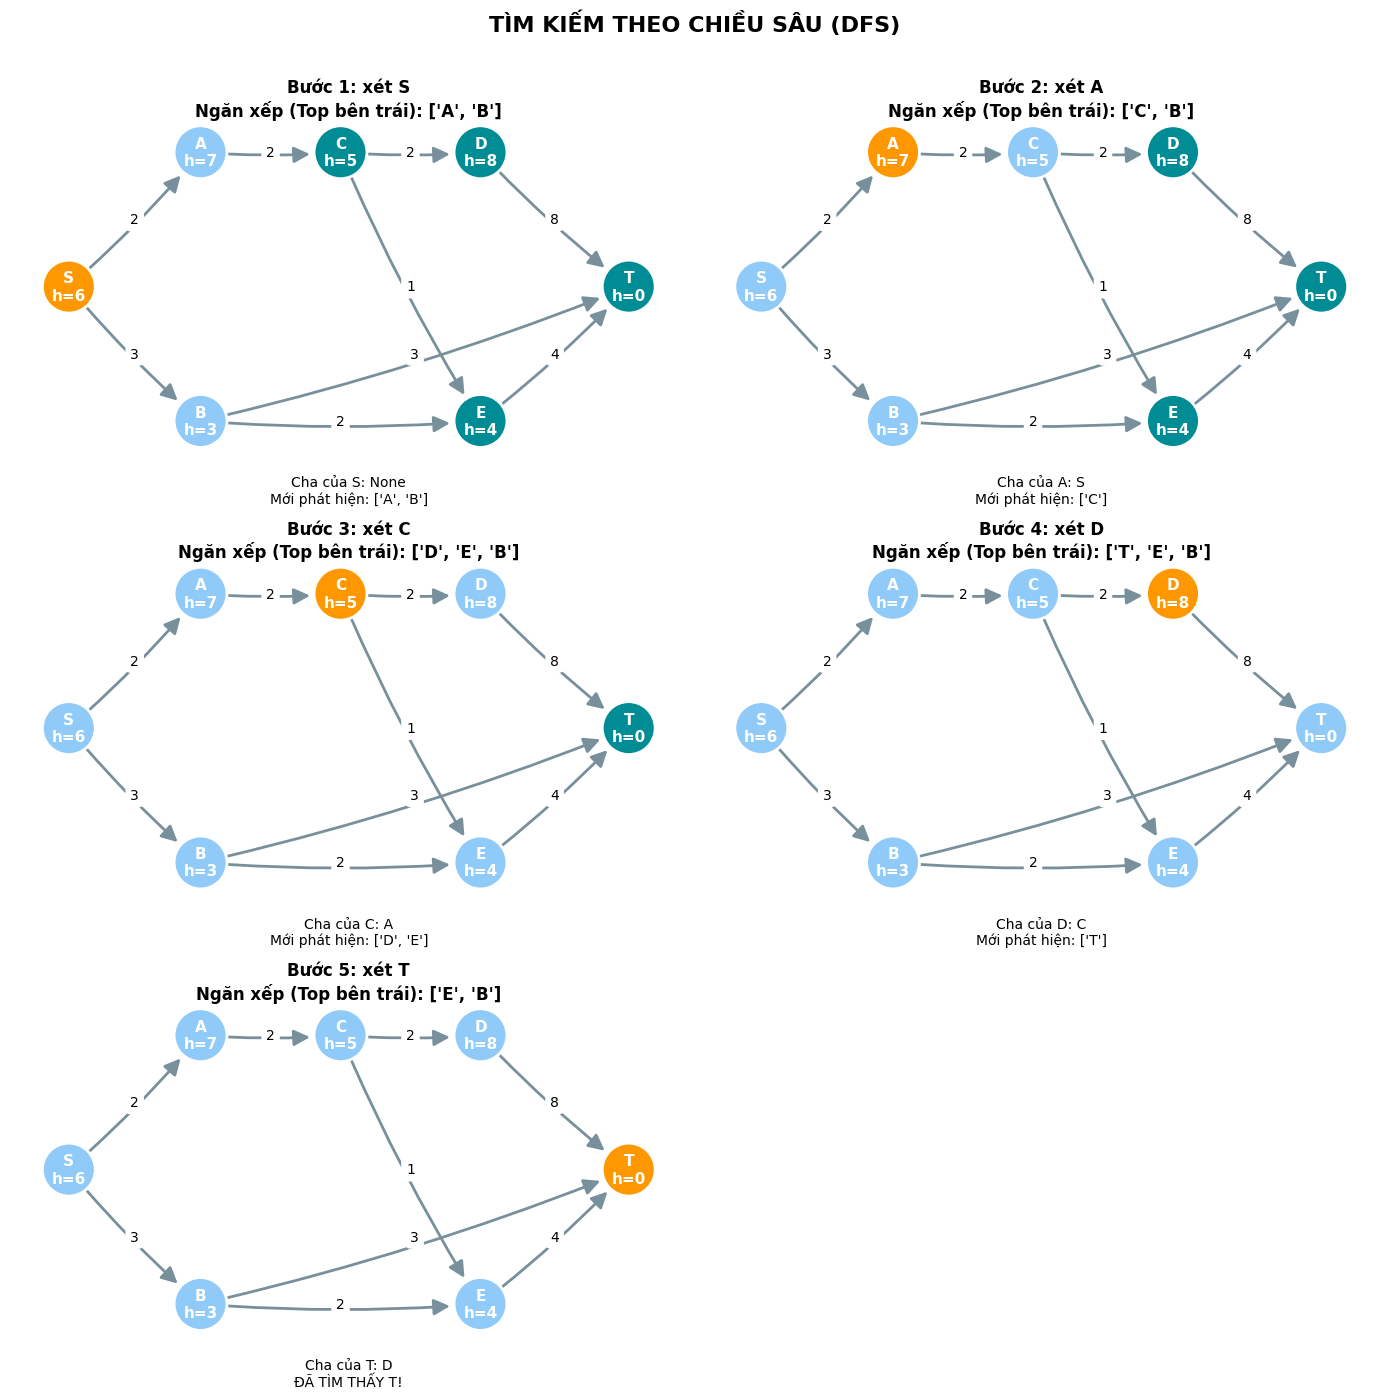

In [46]:
# @title
n_steps=len(dfs_steps);ncols=2;nrows=(n_steps+ncols-1)//ncols
fig,axes=plt.subplots(nrows,ncols,figsize=(14,4.6*nrows));axes=axes.flatten()
for i,s in enumerate(dfs_steps):
    stack_top_left=list(reversed(s['queue']))
    title=f"Bước {i+1}: xét {s['current']}\nNgăn xếp (Top bên trái): {stack_top_left}"
    draw_graph(axes[i],current=s['current'],visited=s['visited'],queue=s['queue'],title=title)
    info=f"Cha của {s['current']}: {s['parent'].get(s['current'])}"
    if s['newly_discovered']:info+=f"\nMới phát hiện: {s['newly_discovered']}"
    if s['found']:info+='\nĐÃ TÌM THẤY T!'
    axes[i].text(.5,-.08,info,transform=axes[i].transAxes,ha='center',va='top',fontsize=10)
for i in range(n_steps,len(axes)):axes[i].axis('off')
plt.suptitle('TÌM KIẾM THEO CHIỀU SÂU (DFS)',fontsize=16,fontweight='bold',y=1.01)
plt.tight_layout();plt.show()

Mỗi hình cho thấy trạng thái DFS sau một lượt xử lý. Ngăn xếp được trình bày sao cho đỉnh sẽ được lấy ra tiếp theo nằm bên trái. Màu sắc thể hiện đỉnh đang xét, đỉnh đã phát hiện và đỉnh còn chờ; mũi tên cho biết chiều đi hợp lệ

In [47]:
# @title
print('='*88)
print(f"{'BƯỚC':<8}{'ĐỈNH XÉT':<13}{'NGĂN XẾP (TOP TRÁI)':<30}{'ĐỈNH MỚI':<20}{'CHA'}")
print('='*88)
for i,s in enumerate(dfs_steps,1):
    top_left=list(reversed(s['queue']))
    print(f"{i:<8}{s['current']:<13}{str(top_left):<30}"
          f"{str(s['newly_discovered']):<20}{s['parent'].get(s['current'])}")
print('='*88)
print('Đường đi DFS:', ' → '.join(dfs_path))

BƯỚC    ĐỈNH XÉT     NGĂN XẾP (TOP TRÁI)           ĐỈNH MỚI            CHA
1       S            ['A', 'B']                    ['A', 'B']          None
2       A            ['C', 'B']                    ['C']               S
3       C            ['D', 'E', 'B']               ['D', 'E']          A
4       D            ['T', 'E', 'B']               ['T']               C
5       T            ['E', 'B']                    []                  D
Đường đi DFS: S → A → C → D → T


Bảng ghi thứ tự lấy đỉnh khỏi ngăn xếp, trạng thái ngăn xếp, các đỉnh mới và quan hệ cha. Ngăn xếp được đảo thứ tự khi hiển thị để người đọc dễ nhận ra đỉnh trên cùng; thứ tự xử lý thực tế không bị thay đổi.

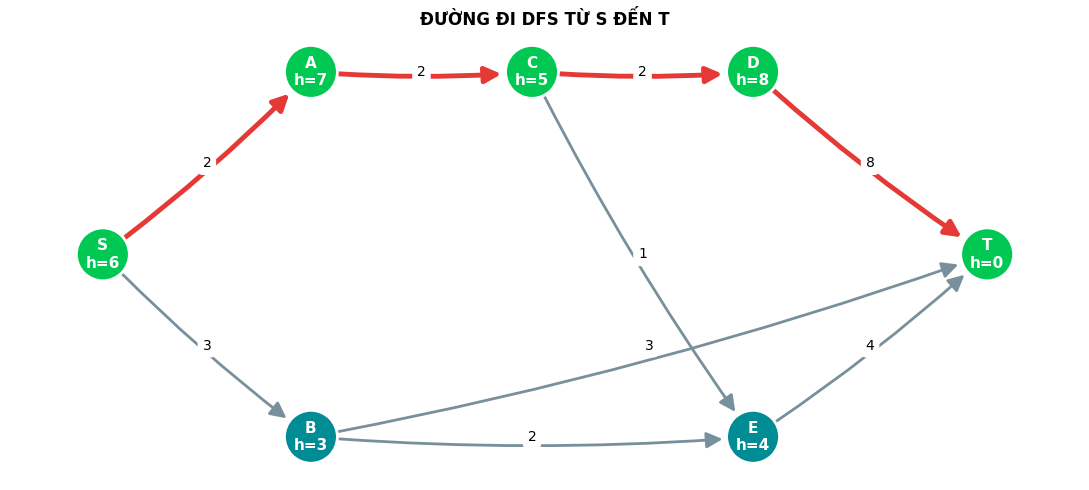

Đường đi DFS: S → A → C → D → T
Số cạnh: 4 | Tổng trọng số: 14


In [48]:
# @title
fig,ax=plt.subplots(figsize=(11,5))
draw_graph(ax,visited=set(dfs_path),path=dfs_path,title='ĐƯỜNG ĐI DFS TỪ S ĐẾN T')
plt.tight_layout();plt.show()
print('Đường đi DFS:', ' → '.join(dfs_path))
print('Số cạnh:',len(dfs_path)-1,'| Tổng trọng số:',path_cost(dfs_path))

Phần này làm nổi bật đường DFS tìm được, rồi in số cạnh và tổng trọng số. Kết quả của DFS phụ thuộc thứ tự duyệt các đỉnh kề. DFS không đảm bảo tìm được đường ít cạnh nhất hoặc có tổng trọng số thấp nhất.

In [49]:
# @title
dfs_sim=[{'current':None,'queue':['S'],'visited':{'S'},'newly_discovered':[],
          'found':False,'message':'Khởi tạo: đưa S vào ngăn xếp.'}]
for s in dfs_steps:dfs_sim.append({**s,'message':f"Xét {s['current']}; đỉnh mới: {s['newly_discovered'] or 'không có'}."})
dfs_i=0;dfs_busy=False
dfs_prev=widgets.Button(description='◀ Bước trước',layout=widgets.Layout(width='125px'))
dfs_next=widgets.Button(description='Bước tiếp ▶',button_style='primary',layout=widgets.Layout(width='125px'))
dfs_play=widgets.Button(description='▶ Chạy tự động',button_style='success',layout=widgets.Layout(width='145px'))
dfs_reset=widgets.Button(description='↺ Đặt lại',button_style='warning',layout=widgets.Layout(width='110px'))
dfs_slider=widgets.IntSlider(value=0,min=0,max=len(dfs_sim)-1,step=1,description='Bước:',continuous_update=False,layout=widgets.Layout(width='95%'))
dfs_output=widgets.Output()

def show_dfs(i):
    global dfs_i,dfs_busy
    if dfs_busy:return
    dfs_busy=True
    try:
        dfs_i=max(0,min(i,len(dfs_sim)-1));s=dfs_sim[dfs_i];top_left=list(reversed(s['queue']))
        with dfs_output:
            clear_output(wait=True);fig,ax=plt.subplots(figsize=(11,5))
            draw_graph(ax,current=s['current'],visited=s['visited'],queue=s['queue'],
                       path=dfs_path if s['found'] else [],title=f"DFS - bước {dfs_i}/{len(dfs_sim)-1}")
            plt.tight_layout();plt.show();plt.close(fig)
            print(s['message']);print('Ngăn xếp (Top bên trái):',top_left)
            print('Đã phát hiện:',sorted(s['visited']))
            if s['found']:print('Đường đi:', ' → '.join(dfs_path),'| chi phí:',path_cost(dfs_path))
        if dfs_slider.value!=dfs_i:dfs_slider.value=dfs_i
    finally:dfs_busy=False

def dfs_slider_changed(ch):
    if ch['name']=='value' and not dfs_busy:show_dfs(ch['new'])
async def dfs_auto(_):
    import asyncio
    dfs_play.disabled=True
    try:
        for j in range(dfs_i+1,len(dfs_sim)):
            show_dfs(j);await asyncio.sleep(1)
    finally:dfs_play.disabled=False
dfs_prev.on_click(lambda _:show_dfs(dfs_i-1));dfs_next.on_click(lambda _:show_dfs(dfs_i+1))
dfs_reset.on_click(lambda _:show_dfs(0));dfs_play.on_click(dfs_auto)
dfs_slider.observe(dfs_slider_changed,names='value')
display(widgets.VBox([widgets.HTML('<h3>Mô phỏng DFS: S → T</h3><p>Top của ngăn xếp được hiển thị bên trái.</p>'),widgets.HBox([dfs_prev,dfs_next,dfs_play,dfs_reset]),dfs_slider,dfs_output]))
show_dfs(0)

Giao diện cho phép xem từng bước DFS bằng các nút và thanh trượt. Mỗi bước hiển thị trạng thái ngăn xếp và các đỉnh đã phát hiện. Khi chạy tự động, giao diện lần lượt chuyển qua các trạng thái để người xem theo dõi quá trình đi sâu trong đồ thị.

In [50]:
# @title
import heapq

def astar_with_steps(graph,edge_list,h,start,goal):
    # Đồ thị có hướng: chỉ lưu trọng số theo chiều khai báo của cạnh
    weights={node:{} for node in graph}
    for u,v,w in edge_list:weights[u][v]=w
    counter=0;heap=[(h[start],0,counter,start)]
    open_nodes={start};closed=set();parent={start:None};g_score={start:0};steps=[]
    while heap:
        f,g_cost,_,current=heapq.heappop(heap)
        if current in closed or g_cost!=g_score.get(current):continue
        open_nodes.discard(current);closed.add(current);newly_discovered=[]
        if current!=goal:
            for neighbor in graph[current]:
                tentative_g=g_cost+weights[current][neighbor]
                if tentative_g<g_score.get(neighbor,float('inf')):
                    is_new=neighbor not in g_score
                    g_score[neighbor]=tentative_g;parent[neighbor]=current;counter+=1
                    heapq.heappush(heap,(tentative_g+h[neighbor],tentative_g,counter,neighbor))
                    open_nodes.add(neighbor)
                    if is_new:newly_discovered.append(neighbor)
        open_display=sorted(open_nodes,key=lambda n:(g_score[n]+h[n],n))
        steps.append({'current':current,'open':open_display,'visited':set(closed),
                      'parent':dict(parent),'g_score':dict(g_score),
                      'newly_discovered':newly_discovered,'found':current==goal,
                      'g':g_cost,'h':h[current],'f':g_cost+h[current]})
        if current==goal:break
    path=[]
    if goal in parent:
        node=goal
        while node is not None:path.append(node);node=parent[node]
        path.reverse()
    return path,g_score.get(goal,float('inf')),steps

astar_path,astar_cost,astar_steps=astar_with_steps(adjacency,edges,heuristic,'S','T')
print('Đỉnh bắt đầu: S | Đỉnh đích: T')
print('Số bước xử lý A*:',len(astar_steps))
print('Đường đi A*:', ' → '.join(astar_path))
print('Tổng trọng số:',astar_cost)

Đỉnh bắt đầu: S | Đỉnh đích: T
Số bước xử lý A*: 3
Đường đi A*: S → B → T
Tổng trọng số: 6


A* chọn đỉnh tiếp theo dựa trên tổng chi phí đã đi và giá trị heuristic. Thuật toán chỉ xét các cạnh theo hướng đã khai báo. Khi tìm thấy đường có chi phí thấp hơn đến một đỉnh, nó cập nhật chi phí và đỉnh cha. Mỗi lượt xét được lưu lại cùng danh sách các đỉnh đang chờ, để có thể trình bày và kiểm tra quá trình lựa chọn.

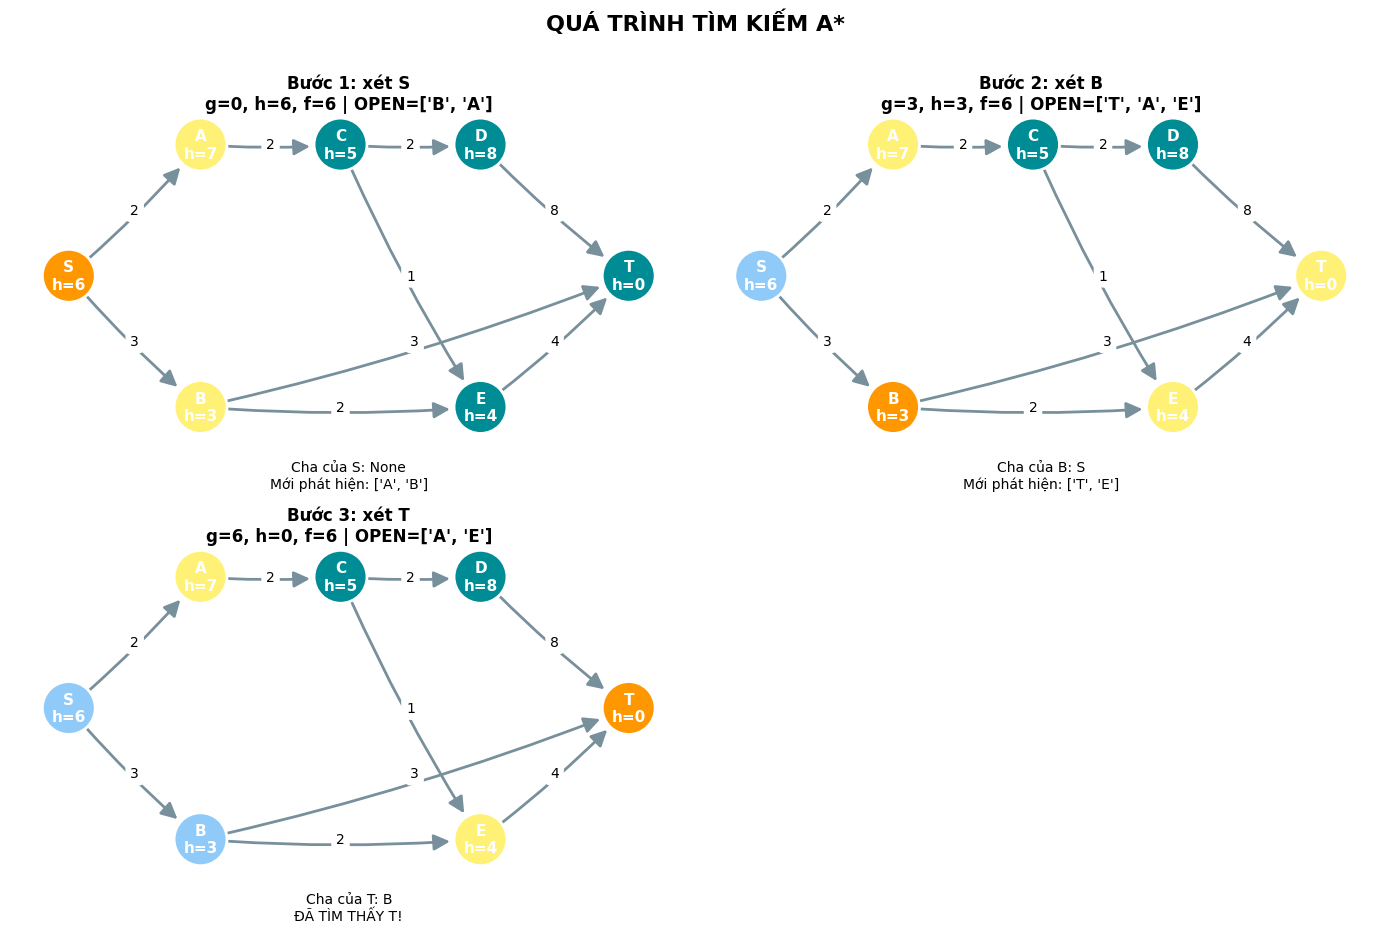

In [51]:
# @title
n_steps=len(astar_steps);ncols=2;nrows=(n_steps+ncols-1)//ncols
fig,axes=plt.subplots(nrows,ncols,figsize=(14,4.6*nrows));axes=axes.flatten()
for i,s in enumerate(astar_steps):
    title=f"Bước {i+1}: xét {s['current']}\ng={s['g']}, h={s['h']}, f={s['f']} | OPEN={s['open']}"
    draw_graph(axes[i],current=s['current'],visited=s['visited'],queue=s['open'],title=title)
    info=f"Cha của {s['current']}: {s['parent'].get(s['current'])}"
    if s['newly_discovered']:info+=f"\nMới phát hiện: {s['newly_discovered']}"
    if s['found']:info+='\nĐÃ TÌM THẤY T!'
    axes[i].text(.5,-.08,info,transform=axes[i].transAxes,ha='center',va='top',fontsize=10)
for i in range(n_steps,len(axes)):axes[i].axis('off')
plt.suptitle('QUÁ TRÌNH TÌM KIẾM A*',fontsize=16,fontweight='bold',y=1.01)
plt.tight_layout();plt.show()

Mỗi hình thể hiện một lượt A*, gồm đỉnh đang xét, các đỉnh còn chờ và trạng thái đã mở rộng. Phần tiêu đề cung cấp các giá trị chi phí để người xem hiểu vì sao thuật toán chọn đỉnh đó. Đồ thị vẫn hiển thị mũi tên để phân biệt hướng di chuyển.

In [52]:
# @title
print('='*100)
print(f"{'BƯỚC':<8}{'ĐỈNH XÉT':<13}{'g':<8}{'h':<8}{'f=g+h':<10}{'OPEN SAU XỬ LÝ':<28}{'ĐỈNH MỚI'}")
print('='*100)
for i,s in enumerate(astar_steps,1):
    print(f"{i:<8}{s['current']:<13}{s['g']:<8}{s['h']:<8}{s['f']:<10}"
          f"{str(s['open']):<28}{s['newly_discovered']}")
print('='*100)
print('Đường đi A*:', ' → '.join(astar_path),'| Tổng trọng số:',astar_cost)

BƯỚC    ĐỈNH XÉT     g       h       f=g+h     OPEN SAU XỬ LÝ              ĐỈNH MỚI
1       S            0       6       6         ['B', 'A']                  ['A', 'B']
2       B            3       3       6         ['T', 'A', 'E']             ['T', 'E']
3       T            6       0       6         ['A', 'E']                  []
Đường đi A*: S → B → T | Tổng trọng số: 6


Bảng ghi thứ tự A* xét các đỉnh và các giá trị được dùng để ưu tiên chúng. Danh sách chờ sau mỗi lượt cho thấy thuật toán còn lựa chọn những đỉnh nào. Bảng này giúp theo dõi cách A* tiến dần từ S về T

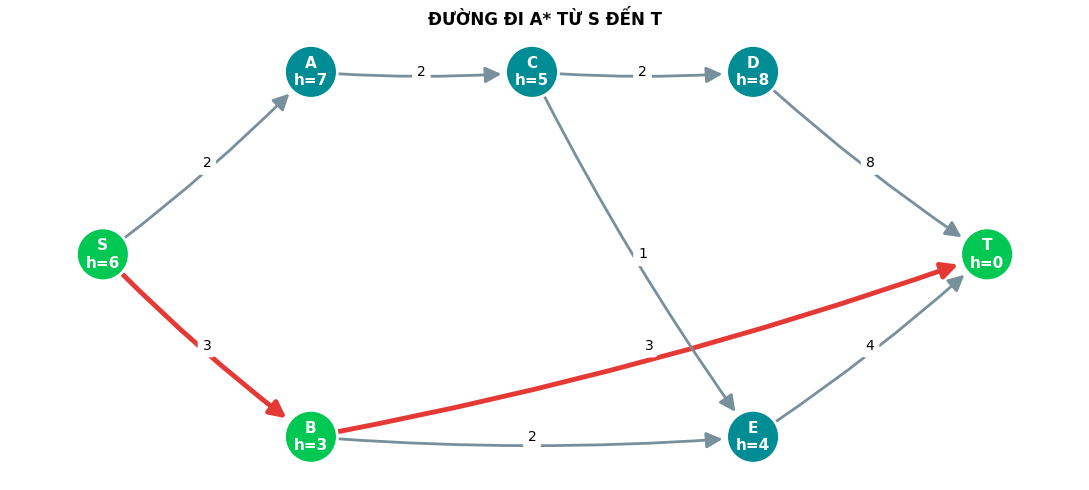

Đường đi A*: S → B → T
Tổng trọng số: 6 | Số cạnh: 2


In [53]:
# @title
fig,ax=plt.subplots(figsize=(11,5))
draw_graph(ax,visited={s['current'] for s in astar_steps},path=astar_path,
           title='ĐƯỜNG ĐI A* TỪ S ĐẾN T')
plt.tight_layout();plt.show()
print('Đường đi A*:', ' → '.join(astar_path))
print('Tổng trọng số:',astar_cost,'| Số cạnh:',len(astar_path)-1)

Phần này tô nổi bật đường đi cuối cùng do A* tìm được. Chương trình tính tổng trọng số bằng cách cộng chi phí của từng cạnh theo đúng chiều đi, rồi in số cạnh và tổng chi phí.

In [54]:
# @title
astar_sim=[{'current':None,'open':['S'],'visited':set(),'parent':{'S':None},
            'g_score':{'S':0},'newly_discovered':[],'found':False,
            'g':0,'h':heuristic['S'],'f':heuristic['S'],
            'message':'Khởi tạo: đưa S vào OPEN với f=g+h.'}]
for s in astar_steps:
    astar_sim.append({**s,'message':f"Xét {s['current']}: g={s['g']}, h={s['h']}, f={s['f']}."})
astar_i=0;astar_busy=False
astar_prev=widgets.Button(description='◀ Bước trước',layout=widgets.Layout(width='125px'))
astar_next=widgets.Button(description='Bước tiếp ▶',button_style='primary',layout=widgets.Layout(width='125px'))
astar_play=widgets.Button(description='▶ Chạy tự động',button_style='success',layout=widgets.Layout(width='145px'))
astar_reset=widgets.Button(description='↺ Đặt lại',button_style='warning',layout=widgets.Layout(width='110px'))
astar_slider=widgets.IntSlider(value=0,min=0,max=len(astar_sim)-1,step=1,description='Bước:',continuous_update=False,layout=widgets.Layout(width='95%'))
astar_output=widgets.Output()

def show_astar(i):
    global astar_i,astar_busy
    if astar_busy:return
    astar_busy=True
    try:
        astar_i=max(0,min(i,len(astar_sim)-1));s=astar_sim[astar_i]
        with astar_output:
            clear_output(wait=True);fig,ax=plt.subplots(figsize=(11,5))
            draw_graph(ax,current=s['current'],visited=s['visited'],queue=s['open'],
                       path=astar_path if s['found'] else [],title=f"A* - bước {astar_i}/{len(astar_sim)-1}")
            plt.tight_layout();plt.show();plt.close(fig)
            print(s['message']);print('OPEN:',s['open']);print('Đã mở rộng:',sorted(s['visited']))
            print('g-score:',s['g_score'])
            if s['found']:print('Đường đi:', ' → '.join(astar_path),'| chi phí:',astar_cost)
        if astar_slider.value!=astar_i:astar_slider.value=astar_i
    finally:astar_busy=False

def astar_slider_changed(ch):
    if ch['name']=='value' and not astar_busy:show_astar(ch['new'])
async def astar_auto(_):
    import asyncio
    astar_play.disabled=True
    try:
        for j in range(astar_i+1,len(astar_sim)):
            show_astar(j);await asyncio.sleep(1)
    finally:astar_play.disabled=False
astar_prev.on_click(lambda _:show_astar(astar_i-1));astar_next.on_click(lambda _:show_astar(astar_i+1))
astar_reset.on_click(lambda _:show_astar(0));astar_play.on_click(astar_auto)
astar_slider.observe(astar_slider_changed,names='value')
display(widgets.VBox([widgets.HTML('<h3>Mô phỏng A*: S → T</h3><p>OPEN ưu tiên đỉnh có f=g+h nhỏ nhất.</p>'),widgets.HBox([astar_prev,astar_next,astar_play,astar_reset]),astar_slider,astar_output]))
show_astar(0)

Giao diện cho phép xem từng trạng thái A* bằng nút lùi, tiến, chạy tự động, đặt lại và thanh trượt. Mỗi bước hiển thị đỉnh đang xét, các đỉnh chờ và chi phí tốt nhất đang biết đến từng đỉnh. Khi thuật toán đến T, giao diện thể hiện đường đi cuối cùng và tổng trọng số.